# Parcial 2 — Computación Flexible
## Optimización Multiobjetivo de Sistemas Difusos Tipo Mamdani mediante Algoritmos Genéticos con PyGAD para el Control de un Servomotor de CD

---

## 1. Introducción y Fundamentos Teóricos

### 1.1. Sistemas de Inferencia Difusa Tipo Mamdani y Control Difuso
Los sistemas de inferencia difusa (FLS, *Fuzzy Logic Systems*) tipo Mamdani permiten diseñar leyes de control no lineales a partir de conocimiento expresado en reglas lingüísticas del tipo `IF antecedente THEN consecuente` (Jang et al., 1997; Nguyen et al., 2003). En un controlador difuso proporcional-derivativo (PD) de posición angular para un servomotor de corriente directa (CD), el controlador recibe en cada instante dos variables de entrada reales:
1. **Error de posición angular:**
   $$e(t) = r(t) - \theta(t) \in \left[-\frac{\pi}{2},\, \frac{\pi}{2}\right]\; [\text{rad}]$$
2. **Cambio (derivada temporal numérica) del error:**
   $$\Delta e(t) = \frac{de(t)}{dt} \approx \frac{e(t_k) - e(t_{k-1})}{\Delta t} \in \left[-\frac{\pi}{6},\, \frac{\pi}{6}\right]\; [\text{rad/s}]$$

y entrega como variable de salida el **voltaje de armadura** aplicado a las terminales del servomotor:
$$v(t) \in [-8.18,\, 8.18]\; [\text{V}]$$

En la arquitectura Mamdani Tipo-1 implementada mediante `scikit-fuzzy` (`skfuzzy` y `skfuzzy.control`), el proceso de inferencia consta de cuatro etapas:
1. **Fuzzificación:** Evaluación de los grados de pertenencia $\mu_{A_i}(e)$ y $\mu_{B_j}(\Delta e)$ sobre funciones de membresía triangulares (`skfuzzy.trimf`) definidas en sus respectivos universos de discurso fijos, manteniendo siempre el orden estricto de sus vértices $a < b < c$.
2. **Evaluación de reglas (conjunción e implicación):** Para cada regla activa $R_{ij}: \text{IF } e \text{ IS } A_i \text{ AND } \Delta e \text{ IS } B_j \text{ THEN } v \text{ IS } C_k$, se calcula la fuerza de disparo mediante la t-norma mínimo $\alpha_{ij} = \min(\mu_{A_i}(e), \mu_{B_j}(\Delta e))$ y se recorta el conjunto consecuente mediante implicación de Mamdani $\mu_{C_k'}(v) = \min(\alpha_{ij}, \mu_{C_k}(v))$.
3. **Agregación:** Combinación de todas las reglas activas mediante la s-norma máximo $\mu_{\text{agg}}(v) = \max_{(i,j)\in\mathcal{A}} \mu_{C_{k(i,j)}'}(v)$.
4. **Defuzzificación:** Obtención del voltaje escalar mediante el método del **centroide** (`skfuzzy.defuzz(..., 'centroid')`):
   $$v(t) = \frac{\int_{-8.18}^{8.18} v \cdot \mu_{\text{agg}}(v)\, dv}{\int_{-8.18}^{8.18} \mu_{\text{agg}}(v)\, dv}$$

### 1.2. Optimización Evolutiva mediante Algoritmos Genéticos (PyGAD) y Función Fitness Multiobjetivo
El ajuste manual de los centros, anchuras, traslapes y base de reglas de un sistema difuso se vuelve intratable conforme crece el número de términos lingüísticos $N \in \{5, 7, 9\}$, pues el número de reglas crece cuadráticamente ($N^2 \in \{25, 49, 81\}$). Los **Algoritmos Genéticos (GA)** implementados en la biblioteca `pygad` permiten evolucionar una población de cromosomas candidatos mediante selección por torneo, cruza de dos puntos, mutación aleatoria acotada y elitismo.

Siguiendo la metodología de **Téllez-Velázquez et al. (2017)** (*"A Feasible Genetic Optimization Strategy for Parametric Interval Type-2 Fuzzy Logic Systems"*, *International Journal of Fuzzy Systems*, DOI `10.1007/s40815-017-0307-0`, Sección 5.1, Ecuaciones 12 y 13, y Tabla 10), la evaluación de cada individuo se realiza mediante la **Función de Aptitud Transitoria Multiobjetivo (MOTFF)** evaluada en las transiciones positiva ($-1 \to +1\text{ rad}$) y negativa ($+1 \to -1\text{ rad}$) de una onda cuadrada de período $100\text{ s}$ durante $T_{\text{sim}} = 200\text{ s}$ (descartando la transición inicial $0 \to +1\text{ rad}$ de los primeros $50\text{ s}$):

$$f_i = w_1 \frac{1}{1 + |OS_i^+|} + w_2 \frac{1}{1 + |SSE_i^+|} + w_3 \frac{t_r^0}{q^+ t_{r_i}^+} + w_4 \frac{t_s^0}{t_{s_i}^+} + w_5 \frac{1}{1 + |OS_i^-|} + w_6 \frac{1}{1 + |SSE_i^-|} + w_7 \frac{t_r^0}{q^- t_{r_i}^-} + w_8 \frac{t_s^0}{t_{s_i}^-} \quad (12)$$

donde las unidades de las medidas de rendimiento corresponden exactamente a la Tabla 10 del artículo ($OS$ en porcentaje `%`, $SSE$ en `rad`, $t_r$ en `s`, $t_s$ en `s`), con constantes obligatorias $t_r^0 = 9\text{ s}$, $t_s^0 = 13\text{ s}$, pesos equitativos $w_1 = \dots = w_8 = 0.125$ ($\sum_{k=1}^8 w_k = 1$), y el **factor de penalización obligatorio del tiempo de crecimiento (Ecuación 13, pág. 10, col. 2, párr. 1)**:

$$q = \frac{\max(h^0) - \min(h_i)}{\max(h) - \min(h)} \ge 1.0 \quad (13)$$

que incrementa el denominador $q \cdot t_r$ cuando $[\min(\theta), \max(\theta)] \subseteq [\min(\theta_0), \max(\theta_0)]$, impidiendo que el algoritmo genético premie tiempos de subida muy cortos e incorrectos cuando el estado estacionario se alcanza por debajo del valor de referencia.

## 2. Configuración del Entorno y Verificación de Versiones Obligatorias

In [1]:
import os
import sys
import time
import timeit
import json
import platform
import numpy as np
import scipy
from scipy.signal import lti, lsim, square
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import pygad
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from src.config import (
    PLANT_NUM, PLANT_DEN, T_SIM, DT, X0, REF_PERIOD,
    ERROR_MIN, ERROR_MAX, DERROR_MIN, DERROR_MAX, VOLTAGE_MIN, VOLTAGE_MAX,
    TR0, TS0, FITNESS_WEIGHTS, EXPERIMENT_SEEDS, SOL_PER_POP, NUM_GENERATIONS
)
from src.plant_sim import create_plant, create_time_and_reference, ClosedLoopPlantSimulator
from src.chromosome import get_num_genes, get_gene_space, create_baseline_chromosome, decode_chromosome
from src.fuzzy_controller import MamdaniFuzzyController, measure_controller_memory_mb
from src.metrics_fitness import compute_penalty_factor_q, compute_step_metrics, evaluate_controller_response
from src.ga_optimizer import evaluate_baseline_controller, run_single_ga_experiment
from src.plotting_tables import summarize_experiments, generate_all_figures
from tests.test_verification import (
    test_plant_and_reference,
    test_equations_12_and_13,
    test_chromosome_encoding_and_repair,
    test_skfuzzy_equivalence,
)

print("=" * 72)
print("VERSIONES DEL ENTORNO DE EJECUCIÓN")
print("=" * 72)
print(f"Python       : {sys.version.split()[0]} ({platform.system()} {platform.release()})")
print(f"numpy        : {np.__version__}")
print(f"scipy        : {scipy.__version__}")
print(f"scikit-fuzzy : {fuzz.__version__}")
print(f"pygad        : {pygad.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")
print("=" * 72)

VERSIONES DEL ENTORNO DE EJECUCIÓN
Python       : 3.14.2 (Windows 11)
numpy        : 2.4.2
scipy        : 1.18.1
scikit-fuzzy : 0.5.0
pygad        : 3.9.2
matplotlib   : 3.10.8


## 3. Metodología, Planta, Universos de Discurso y Codificación Genética

### 3.1. Planta del Sistema y Simulación Estricta con `scipy.signal.lsim`
La función de transferencia continua del servomotor de CD (Ecuación 10 del artículo de referencia y páginas 1, 2 y 12 de `Parcial 2.pdf`) es:
$$G(s) = \frac{0.5}{s^3 + 13.6667 s^2 + 23.3487 s}$$
Se construye mediante `G = lti([0.5], [1, 13.6667, 23.3487, 0])` y se simula en el intervalo exacto $t \in [0, 200]\text{ s}$ con paso $\Delta t = 0.10\text{ s}$ ($2,001$ muestras, $f_s = 10\text{ Hz}$), condiciones iniciales nulas `x0 = [0, 0, 0]`, sin ruido ni perturbaciones, invocando **exclusivamente `scipy.signal.lsim`** tanto en la propagación paso a paso de lazo cerrado como en la verificación de trayectoria completa `tout, theta, xout = lsim(G, U=u, T=t, X0=x0)`.

### 3.2. Codificación Genética, Funciones Triangulares y Orden Estricto $a < b < c$
Para cada configuración de $N \in \{5, 7, 9\}$ términos lingüísticos por variable (`error`, `derror`, `voltage`):
* **Genes de funciones de membresía ($9N$ genes):** Para cada una de las 3 variables se codifican $N$ centros $b_k \in (U_{\min}, U_{\max})$ y $2N$ factores de anchura/traslape izquierdo y derecho $(w_{L,k}, w_{R,k}) \in [0.20, 1.80]$. El decodificador ordena los centros ($b_0 < b_1 < \dots < b_{N-1}$) y construye los conjuntos triangulares (`skfuzzy.trimf`) con parámetros $[a_k, b_k, c_k] \subseteq [U_{\min}, U_{\max}]$ cuidando que **siempre exista un orden estricto $a_k < b_k < c_k$** y que se formen los traslapes entre conjuntos vecinos ($c_k > a_{k+1}$).
* **Genes de activación de reglas ($N^2$ genes):** Valores en $[0, 1]$ donde $g \ge 0.5 \implies 1$ (regla activa) y $g < 0.5 \implies 0$ (regla desactivada). Si todas las reglas se apagan, el mecanismo de reparación activa la regla central `(ZE, ZE) -> ZE` y aplica una penalización.
* **Genes de consecuentes de reglas ($N^2$ genes):** Índices en $[0, N-1]$ redondeados al entero más cercano que seleccionan el término lingüístico de voltaje para cada regla.
* **Longitud total del cromosoma:** $L(N) = 9N + 2N^2 \implies \mathbf{95\text{ genes}}$ ($N=5$), $\mathbf{161\text{ genes}}$ ($N=7$) y $\mathbf{243\text{ genes}}$ ($N=9$).

In [2]:
# Ejecución de las pruebas unitarias de verificación matemática y técnica
test_plant_and_reference()
test_equations_12_and_13()
test_chromosome_encoding_and_repair()
test_skfuzzy_equivalence()

G = create_plant()
t, r = create_time_and_reference()
print(f"Planta G(s) numerador: {G.num}, denominador: {G.den}")
print(f"Horizonte temporal: [{t[0]:.1f}, {t[-1]:.1f}] s con dt = {DT} s ({len(t)} muestras)")
for label_cfg, n_t in [("Controlador A", 5), ("Controlador B", 7), ("Controlador C", 9)]:
    print(f"{label_cfg} ({n_t} términos): {get_num_genes(n_t)} genes optimizables ({n_t**2} reglas posibles)")

[OK] test_plant_and_reference (con verificación estricta de lsim) superado.
[OK] test_equations_12_and_13 (con OS en % y q >= 1.0 según Ec. 13) superado.
[OK] test_chromosome_encoding_and_repair (con orden estricto a < b < c y traslapes) superado.


[OK] test_skfuzzy_equivalence superado (precisión < 1e-4 V).
Planta G(s) numerador: [0.5], denominador: [ 1.     13.6667 23.3487  0.    ]
Horizonte temporal: [0.0, 200.0] s con dt = 0.1 s (2001 muestras)
Controlador A (5 términos): 95 genes optimizables (25 reglas posibles)
Controlador B (7 términos): 161 genes optimizables (49 reglas posibles)
Controlador C (9 términos): 243 genes optimizables (81 reglas posibles)


## 4. Protocolo Experimental — Fase 1: Implementación y Evaluación de los Controladores Base (`automf`)
Antes de aplicar la optimización evolutiva, se evalúan los tres controladores iniciales generados con `automf` y con todas sus reglas activas ($25, 49$ y $81$ reglas).

Baseline 5 términos (25 reglas activas):
  Fitness = 0.6319 | q+ = 1.0349, q- = 1.0283
  OS+ = 0.0000%, OS- = 0.0000% | SSE+ = 0.0435 rad, SSE- = 0.0387 rad
  tr+ = 30.60 s, tr- = 30.20 s | ts+ = 47.20 s, ts- = 45.60 s
  Tiempo inferencia = 10.112 ms | Memoria = 0.587 MB



Baseline 7 términos (49 reglas activas):
  Fitness = 0.6421 | q+ = 1.0291, q- = 1.0242
  OS+ = 0.0000%, OS- = 0.0000% | SSE+ = 0.0411 rad, SSE- = 0.0349 rad
  tr+ = 28.20 s, tr- = 27.65 s | ts+ = 45.70 s, ts- = 43.65 s
  Tiempo inferencia = 25.596 ms | Memoria = 1.163 MB



Baseline 9 términos (81 reglas activas):
  Fitness = 0.6459 | q+ = 1.0283, q- = 1.0238
  OS+ = 0.0000%, OS- = 0.0000% | SSE+ = 0.0407 rad, SSE- = 0.0343 rad
  tr+ = 27.20 s, tr- = 26.55 s | ts+ = 45.40 s, ts- = 43.25 s
  Tiempo inferencia = 50.063 ms | Memoria = 2.278 MB



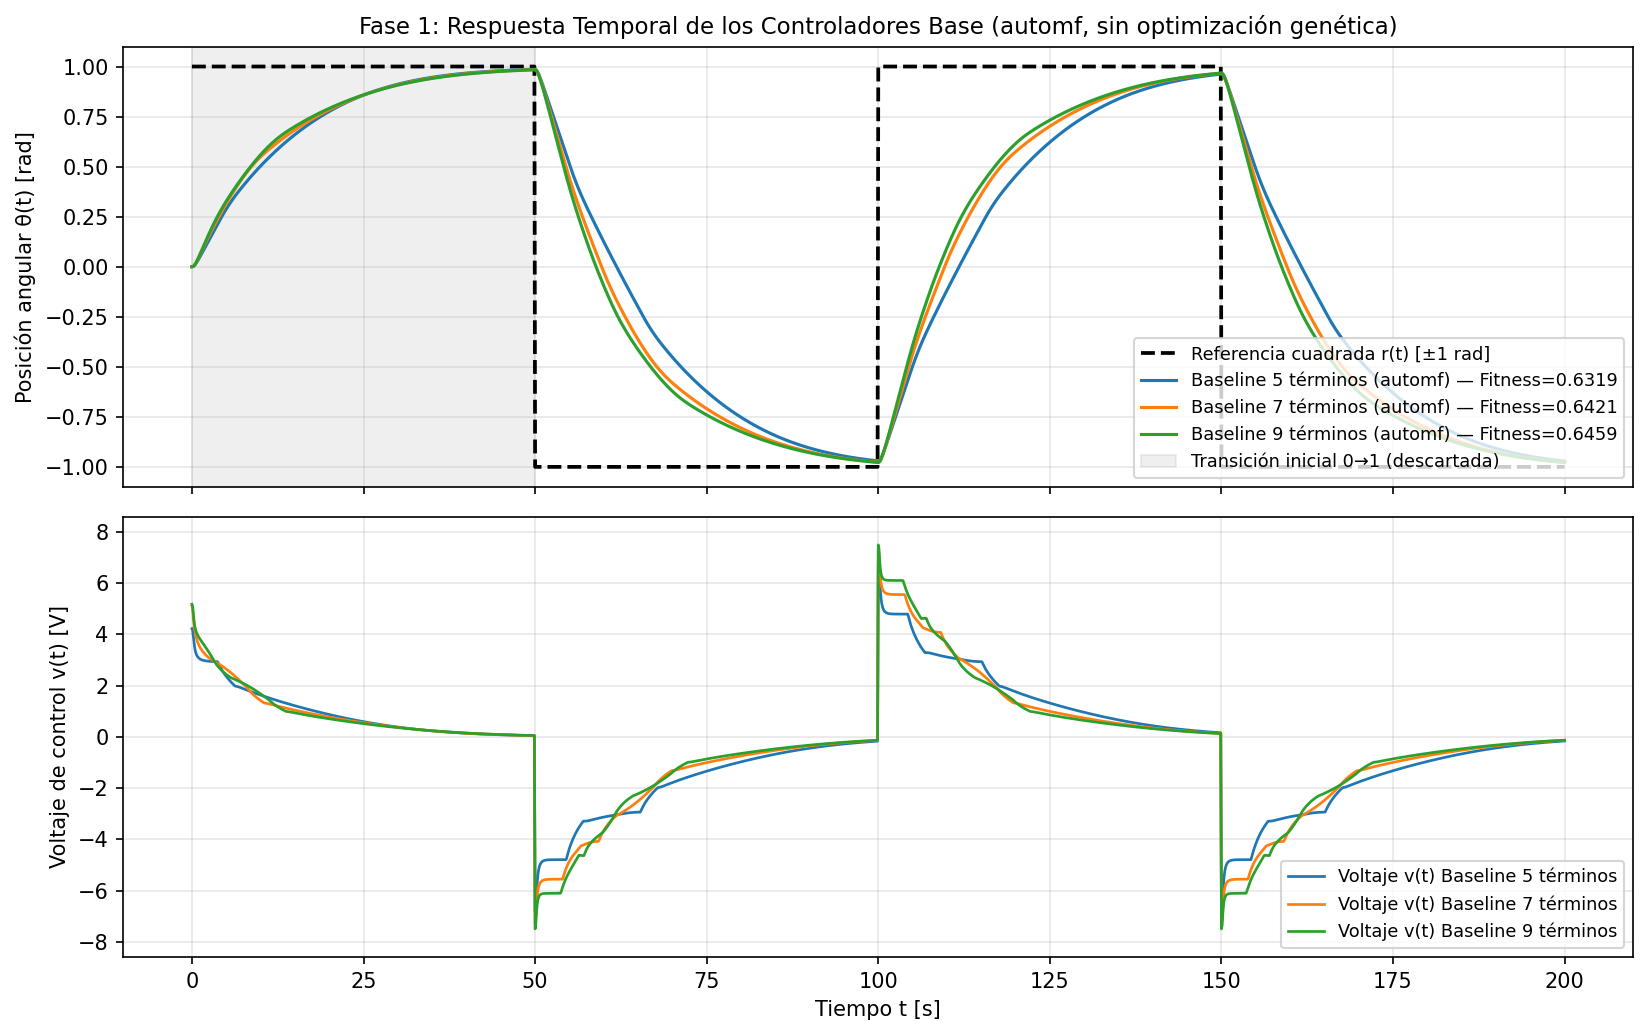

In [3]:
baselines = {}
for n_terms in [5, 7, 9]:
    baselines[n_terms] = evaluate_baseline_controller(n_terms)
    m = baselines[n_terms]["metrics"]
    print(
        f"Baseline {n_terms} términos ({baselines[n_terms]['num_active_rules']} reglas activas):\n"
        f"  Fitness = {m['fitness']:.4f} | q+ = {m['q_pos']:.4f}, q- = {m['q_neg']:.4f}\n"
        f"  OS+ = {m['OS_pos']:.4f}%, OS- = {m['OS_neg']:.4f}% | SSE+ = {m['SSE_pos']:.4f} rad, SSE- = {m['SSE_neg']:.4f} rad\n"
        f"  tr+ = {m['tr_pos']:.2f} s, tr- = {m['tr_neg']:.2f} s | ts+ = {m['ts_pos']:.2f} s, ts- = {m['ts_neg']:.2f} s\n"
        f"  Tiempo inferencia = {baselines[n_terms]['inference_time_ms']:.3f} ms | Memoria = {baselines[n_terms]['memory_mb']:.3f} MB\n"
    )

display(Image(filename="results/figures/fig1_baselines_response.png"))

## 5. Protocolo Experimental — Fases 2, 3, 4 y 5: Optimización con PyGAD, Selección, Costo Computacional y Repetibilidad (5 Semillas)
Se ejecutan (o cargan desde los archivos auditables en `results/runs/` generados por las corridas reales; cambie `FORCE_RERUN = True` si desea volver a correr las 15 optimizaciones desde cero) las **5 ejecuciones independientes** con semillas distintas `EXPERIMENT_SEEDS = [42, 100, 2026, 777, 999]` para cada configuración ($N \in \{5, 7, 9\}$), utilizando `sol_per_pop = 20` y `num_generations = 30`.

In [4]:
FORCE_RERUN = False  # Cambiar a True para re-ejecutar las 15 corridas completas

runs_by_terms = {5: [], 7: [], 9: []}
for n_terms in [5, 7, 9]:
    print(f"=== Resultados de las 5 ejecuciones independientes: Controlador de {n_terms} términos ===")
    for idx, seed in enumerate(EXPERIMENT_SEEDS, start=1):
        rec = run_single_ga_experiment(
            n_terms=n_terms,
            seed=seed,
            sol_per_pop=SOL_PER_POP,
            num_generations=NUM_GENERATIONS,
            force_rerun=FORCE_RERUN,
        )
        runs_by_terms[n_terms].append(rec)
        m = rec["metrics"]
        print(
            f"  Ejecución {idx}/5 (semilla={seed:4d}): Fitness={m['fitness']:.4f} | "
            f"OS+={m['OS_pos']:.4f}%, OS-={m['OS_neg']:.4f}% | "
            f"SSE+={m['SSE_pos']:.4f}, SSE-={m['SSE_neg']:.4f} | "
            f"tr+={m['tr_pos']:.2f}s, tr-={m['tr_neg']:.2f}s | "
            f"ts+={m['ts_pos']:.2f}s, ts-={m['ts_neg']:.2f}s | "
            f"Reglas={rec['num_active_rules']}/{rec['total_possible_rules']} | "
            f"Opt={rec['optimization_time_s']:.2f}s | Inf={rec['inference_time_ms']:.3f}ms | Mem={rec['memory_mb']:.3f}MB"
        )
    print()

summary = summarize_experiments(baselines, runs_by_terms)
figure_paths = generate_all_figures(baselines, runs_by_terms, summary)

=== Resultados de las 5 ejecuciones independientes: Controlador de 5 términos ===
  Ejecución 1/5 (semilla=  42): Fitness=0.7499 | OS+=0.0000%, OS-=0.0000% | SSE+=0.0211, SSE-=0.0604 | tr+=14.50s, tr-=17.40s | ts+=17.90s, ts-=50.00s | Reglas=15/25 | Opt=168.21s | Inf=10.121ms | Mem=0.461MB
  Ejecución 2/5 (semilla= 100): Fitness=0.7554 | OS+=0.0000%, OS-=1.2194% | SSE+=0.0158, SSE-=0.0127 | tr+=11.70s, tr-=16.60s | ts+=16.10s, ts-=25.50s | Reglas=20/25 | Opt=170.00s | Inf=10.602ms | Mem=0.512MB
  Ejecución 3/5 (semilla=2026): Fitness=0.6924 | OS+=0.0000%, OS-=0.0000% | SSE+=0.1286, SSE-=0.0562 | tr+=15.80s, tr-=12.20s | ts+=50.00s, ts-=50.00s | Reglas=14/25 | Opt=168.87s | Inf=8.898ms | Mem=0.460MB
  Ejecución 4/5 (semilla= 777): Fitness=0.6499 | OS+=0.0000%, OS-=0.0000% | SSE+=0.0264, SSE-=0.0324 | tr+=25.80s, tr-=32.40s | ts+=36.70s, ts-=45.40s | Reglas=22/25 | Opt=172.01s | Inf=10.856ms | Mem=0.545MB
  Ejecución 5/5 (semilla= 999): Fitness=0.7616 | OS+=0.0577%, OS-=0.0000% | SSE+=0.

## 6. Resultados Experimentales y Tabla Obligatoria de Resultados

### Tabla Obligatoria de Resultados (`Parcial 2.pdf`, pág. 10)

| Métrica | 5 términos (Controlador A) | 7 términos (Controlador B) | 9 términos (Controlador C) |
| :--- | :---: | :---: | :---: |
| **Fitness promedio** (5 corridas) | 0.7218 ± 0.0488 | 0.7299 ± 0.0593 | 0.7134 ± 0.0649 |
| **Fitness máximo** (mejor corrida) | **0.7616** (semilla 999) | **0.8199** (semilla 42) | **0.7946** (semilla 999) |
| $OS^+$ (%) | 0.0577 (media: 0.0115 ± 0.0258) | 0.7896 (media: 1.2004 ± 1.3434) | 0.0000 (media: 0.4326 ± 0.9673) |
| $OS^-$ (%) | 0.0000 (media: 0.2439 ± 0.5453) | 0.0000 (media: 0.0000 ± 0.0000) | 1.3638 (media: 1.2498 ± 1.9562) |
| $SSE^+$ (rad) | 0.0031 (media: 0.0390 ± 0.0508) | 0.0063 (media: 0.0213 ± 0.0089) | 0.0144 (media: 0.0879 ± 0.1139) |
| $SSE^-$ (rad) | 0.0104 (media: 0.0344 ± 0.0235) | 0.0060 (media: 0.0379 ± 0.0303) | 0.0122 (media: 0.0478 ± 0.0649) |
| $t_r^+$ (s) | 11.70 (media: 15.90 ± 5.82) | 13.40 (media: 17.50 ± 5.85) | 14.70 (media: 21.80 ± 16.08) |
| $t_r^-$ (s) | 30.40 (media: 21.80 ± 9.01) | 11.70 (media: 14.90 ± 3.99) | 11.30 (media: 18.99 ± 10.64) |
| $t_s^+$ (s) | 16.80 (media: 27.50 ± 15.23) | 17.60 (media: 27.38 ± 10.96) | 18.60 (media: 30.60 ± 17.79) |
| $t_s^-$ (s) | 40.40 (media: 42.26 ± 10.17) | 15.60 (media: 30.45 ± 16.94) | 15.10 (media: 24.36 ± 14.90) |
| **Reglas activas** (mejor / media ± DE) | 16 / 25 (17.4 ± 3.4) | 39 / 49 (35.8 ± 4.1) | 58 / 81 (54.4 ± 7.8) |
| **Número de parámetros optimizados** | 95 genes | 161 genes | 243 genes |
| **Tiempo de optimización (s)** | 169.63 ± 1.47 s | 172.32 ± 0.76 s | 181.87 ± 0.81 s |
| **Tiempo promedio de inferencia (ms)** | 10.065 ± 0.762 ms | 22.761 ± 2.088 ms | 36.585 ± 5.642 ms |
| **Uso de memoria (MB)** | 0.491 ± 0.037 MB | 0.884 ± 0.071 MB | 1.436 ± 0.205 MB |

---

### 6.1. Listado Explícito de Reglas Activas de la Mejor Solución por Configuración

#### A) Mejor Controlador de 5 Términos (Semilla 999, Fitness = 0.7616, **16 / 25 reglas activas**):
1. `R01 (celda [1,1]): IF error IS NB AND derror IS NB THEN voltage IS PB`
2. `R02 (celda [1,2]): IF error IS NB AND derror IS NS THEN voltage IS NB`
3. `R03 (celda [1,3]): IF error IS NB AND derror IS ZE THEN voltage IS NS`
4. `R04 (celda [1,4]): IF error IS NB AND derror IS PS THEN voltage IS ZE`
5. `R06 (celda [2,1]): IF error IS NS AND derror IS NB THEN voltage IS NS`
6. `R09 (celda [2,4]): IF error IS NS AND derror IS PS THEN voltage IS NS`
7. `R10 (celda [2,5]): IF error IS NS AND derror IS PB THEN voltage IS NS`
8. `R11 (celda [3,1]): IF error IS ZE AND derror IS NB THEN voltage IS NB`
9. `R15 (celda [3,5]): IF error IS ZE AND derror IS PB THEN voltage IS PB`
10. `R17 (celda [4,2]): IF error IS PS AND derror IS NS THEN voltage IS NB`
11. `R19 (celda [4,4]): IF error IS PS AND derror IS PS THEN voltage IS PB`
12. `R20 (celda [4,5]): IF error IS PS AND derror IS PB THEN voltage IS ZE`
13. `R22 (celda [5,2]): IF error IS PB AND derror IS NS THEN voltage IS PS`
14. `R23 (celda [5,3]): IF error IS PB AND derror IS ZE THEN voltage IS PB`
15. `R24 (celda [5,4]): IF error IS PB AND derror IS PS THEN voltage IS PB`
16. `R25 (celda [5,5]): IF error IS PB AND derror IS PB THEN voltage IS PB`

#### B) Mejor Controlador de 7 Términos (Semilla 42, Fitness = 0.8199, **39 / 49 reglas activas**):
1. `R01 (celda [1,1]): IF error IS NB AND derror IS NB THEN voltage IS NB`
2. `R02 (celda [1,2]): IF error IS NB AND derror IS NM THEN voltage IS NB`
3. `R03 (celda [1,3]): IF error IS NB AND derror IS NS THEN voltage IS NB`
4. `R04 (celda [1,4]): IF error IS NB AND derror IS ZE THEN voltage IS NM`
5. `R06 (celda [1,6]): IF error IS NB AND derror IS PM THEN voltage IS NM`
6. `R07 (celda [1,7]): IF error IS NB AND derror IS PB THEN voltage IS ZE`
7. `R08 (celda [2,1]): IF error IS NM AND derror IS NB THEN voltage IS PS`
8. `R09 (celda [2,2]): IF error IS NM AND derror IS NM THEN voltage IS NB`
9. `R10 (celda [2,3]): IF error IS NM AND derror IS NS THEN voltage IS NB`
10. `R11 (celda [2,4]): IF error IS NM AND derror IS ZE THEN voltage IS NB`
11. `R12 (celda [2,5]): IF error IS NM AND derror IS PS THEN voltage IS NM`
12. `R13 (celda [2,6]): IF error IS NM AND derror IS PM THEN voltage IS PB`
13. `R14 (celda [2,7]): IF error IS NM AND derror IS PB THEN voltage IS PS`
14. `R15 (celda [3,1]): IF error IS NS AND derror IS NB THEN voltage IS PM`
15. `R17 (celda [3,3]): IF error IS NS AND derror IS NS THEN voltage IS NB`
16. `R18 (celda [3,4]): IF error IS NS AND derror IS ZE THEN voltage IS NM`
17. `R19 (celda [3,5]): IF error IS NS AND derror IS PS THEN voltage IS NS`
18. `R20 (celda [3,6]): IF error IS NS AND derror IS PM THEN voltage IS PS`
19. `R21 (celda [3,7]): IF error IS NS AND derror IS PB THEN voltage IS NM`
20. `R22 (celda [4,1]): IF error IS ZE AND derror IS NB THEN voltage IS NB`
21. `R23 (celda [4,2]): IF error IS ZE AND derror IS NM THEN voltage IS NB`
22. `R25 (celda [4,4]): IF error IS ZE AND derror IS ZE THEN voltage IS ZE`
23. `R26 (celda [4,5]): IF error IS ZE AND derror IS PS THEN voltage IS PS`
24. `R27 (celda [4,6]): IF error IS ZE AND derror IS PM THEN voltage IS PM`
25. `R30 (celda [5,2]): IF error IS PS AND derror IS NM THEN voltage IS NS`
26. `R31 (celda [5,3]): IF error IS PS AND derror IS NS THEN voltage IS PM`
27. `R32 (celda [5,4]): IF error IS PS AND derror IS ZE THEN voltage IS PM`
28. `R34 (celda [5,6]): IF error IS PS AND derror IS PM THEN voltage IS PB`
29. `R35 (celda [5,7]): IF error IS PS AND derror IS PB THEN voltage IS PB`
30. `R37 (celda [6,2]): IF error IS PM AND derror IS NM THEN voltage IS ZE`
31. `R39 (celda [6,4]): IF error IS PM AND derror IS ZE THEN voltage IS PM`
32. `R40 (celda [6,5]): IF error IS PM AND derror IS PS THEN voltage IS PM`
33. `R41 (celda [6,6]): IF error IS PM AND derror IS PM THEN voltage IS ZE`
34. `R42 (celda [6,7]): IF error IS PM AND derror IS PB THEN voltage IS PB`
35. `R43 (celda [7,1]): IF error IS PB AND derror IS NB THEN voltage IS PS`
36. `R44 (celda [7,2]): IF error IS PB AND derror IS NM THEN voltage IS PS`
37. `R46 (celda [7,4]): IF error IS PB AND derror IS ZE THEN voltage IS PM`
38. `R47 (celda [7,5]): IF error IS PB AND derror IS PS THEN voltage IS PB`
39. `R48 (celda [7,6]): IF error IS PB AND derror IS PM THEN voltage IS PB`

#### C) Mejor Controlador de 9 Términos (Semilla 999, Fitness = 0.7946, **58 / 81 reglas activas**):
1. `R01 (celda [1,1]): IF error IS NVB AND derror IS NVB THEN voltage IS PB`
2. `R02 (celda [1,2]): IF error IS NVB AND derror IS NB THEN voltage IS NVB`
3. `R05 (celda [1,5]): IF error IS NVB AND derror IS ZE THEN voltage IS NVB`
4. `R07 (celda [1,7]): IF error IS NVB AND derror IS PM THEN voltage IS NM`
5. `R09 (celda [1,9]): IF error IS NVB AND derror IS PVB THEN voltage IS NS`
6. `R10 (celda [2,1]): IF error IS NB AND derror IS NVB THEN voltage IS PM`
7. `R11 (celda [2,2]): IF error IS NB AND derror IS NB THEN voltage IS NVB`
8. `R12 (celda [2,3]): IF error IS NB AND derror IS NM THEN voltage IS NVB`
9. `R14 (celda [2,5]): IF error IS NB AND derror IS ZE THEN voltage IS NVB`
10. `R15 (celda [2,6]): IF error IS NB AND derror IS PS THEN voltage IS NB`
11. `R16 (celda [2,7]): IF error IS NB AND derror IS PM THEN voltage IS NS`
12. `R17 (celda [2,8]): IF error IS NB AND derror IS PB THEN voltage IS ZE`
13. `R20 (celda [3,2]): IF error IS NM AND derror IS NB THEN voltage IS NVB`
14. `R22 (celda [3,4]): IF error IS NM AND derror IS NS THEN voltage IS PS`
15. `R23 (celda [3,5]): IF error IS NM AND derror IS ZE THEN voltage IS NM`
16. `R24 (celda [3,6]): IF error IS NM AND derror IS PS THEN voltage IS NS`
17. `R25 (celda [3,7]): IF error IS NM AND derror IS PM THEN voltage IS NB`
18. `R28 (celda [4,1]): IF error IS NS AND derror IS NVB THEN voltage IS NB`
19. `R29 (celda [4,2]): IF error IS NS AND derror IS NB THEN voltage IS NVB`
20. `R32 (celda [4,5]): IF error IS NS AND derror IS ZE THEN voltage IS NM`
21. `R34 (celda [4,7]): IF error IS NS AND derror IS PM THEN voltage IS NS`
22. `R35 (celda [4,8]): IF error IS NS AND derror IS PB THEN voltage IS PVB`
23. `R36 (celda [4,9]): IF error IS NS AND derror IS PVB THEN voltage IS PM`
24. `R37 (celda [5,1]): IF error IS ZE AND derror IS NVB THEN voltage IS PM`
25. `R39 (celda [5,3]): IF error IS ZE AND derror IS NM THEN voltage IS PB`
26. `R40 (celda [5,4]): IF error IS ZE AND derror IS NS THEN voltage IS NS`
27. `R41 (celda [5,5]): IF error IS ZE AND derror IS ZE THEN voltage IS ZE`
28. `R42 (celda [5,6]): IF error IS ZE AND derror IS PS THEN voltage IS NM`
29. `R43 (celda [5,7]): IF error IS ZE AND derror IS PM THEN voltage IS PVB`
30. `R44 (celda [5,8]): IF error IS ZE AND derror IS PB THEN voltage IS NM`
31. `R46 (celda [6,1]): IF error IS PS AND derror IS NVB THEN voltage IS PM`
32. `R47 (celda [6,2]): IF error IS PS AND derror IS NB THEN voltage IS ZE`
33. `R48 (celda [6,3]): IF error IS PS AND derror IS NM THEN voltage IS NVB`
34. `R49 (celda [6,4]): IF error IS PS AND derror IS NS THEN voltage IS PB`
35. `R50 (celda [6,5]): IF error IS PS AND derror IS ZE THEN voltage IS PS`
36. `R52 (celda [6,7]): IF error IS PS AND derror IS PM THEN voltage IS PB`
37. `R54 (celda [6,9]): IF error IS PS AND derror IS PVB THEN voltage IS PM`
38. `R55 (celda [7,1]): IF error IS PM AND derror IS NVB THEN voltage IS ZE`
39. `R56 (celda [7,2]): IF error IS PM AND derror IS NB THEN voltage IS NB`
40. `R58 (celda [7,4]): IF error IS PM AND derror IS NS THEN voltage IS PS`
41. `R60 (celda [7,6]): IF error IS PM AND derror IS PS THEN voltage IS NM`
42. `R61 (celda [7,7]): IF error IS PM AND derror IS PM THEN voltage IS NS`
43. `R62 (celda [7,8]): IF error IS PM AND derror IS PB THEN voltage IS NS`
44. `R63 (celda [7,9]): IF error IS PM AND derror IS PVB THEN voltage IS PVB`
45. `R64 (celda [8,1]): IF error IS PB AND derror IS NVB THEN voltage IS ZE`
46. `R65 (celda [8,2]): IF error IS PB AND derror IS NB THEN voltage IS ZE`
47. `R66 (celda [8,3]): IF error IS PB AND derror IS NM THEN voltage IS PVB`
48. `R67 (celda [8,4]): IF error IS PB AND derror IS NS THEN voltage IS PM`
49. `R68 (celda [8,5]): IF error IS PB AND derror IS ZE THEN voltage IS PVB`
50. `R70 (celda [8,7]): IF error IS PB AND derror IS PM THEN voltage IS PS`
51. `R71 (celda [8,8]): IF error IS PB AND derror IS PB THEN voltage IS PS`
52. `R72 (celda [8,9]): IF error IS PB AND derror IS PVB THEN voltage IS PVB`
53. `R73 (celda [9,1]): IF error IS PVB AND derror IS NVB THEN voltage IS NS`
54. `R74 (celda [9,2]): IF error IS PVB AND derror IS NB THEN voltage IS PS`
55. `R76 (celda [9,4]): IF error IS PVB AND derror IS NS THEN voltage IS PVB`
56. `R77 (celda [9,5]): IF error IS PVB AND derror IS ZE THEN voltage IS PVB`
57. `R78 (celda [9,6]): IF error IS PVB AND derror IS PS THEN voltage IS PVB`
58. `R80 (celda [9,8]): IF error IS PVB AND derror IS PB THEN voltage IS PB`

## 7. Gráficas de Respuesta Temporal, Convergencia, Funciones de Membresía, Reglas Activas y Costo Computacional

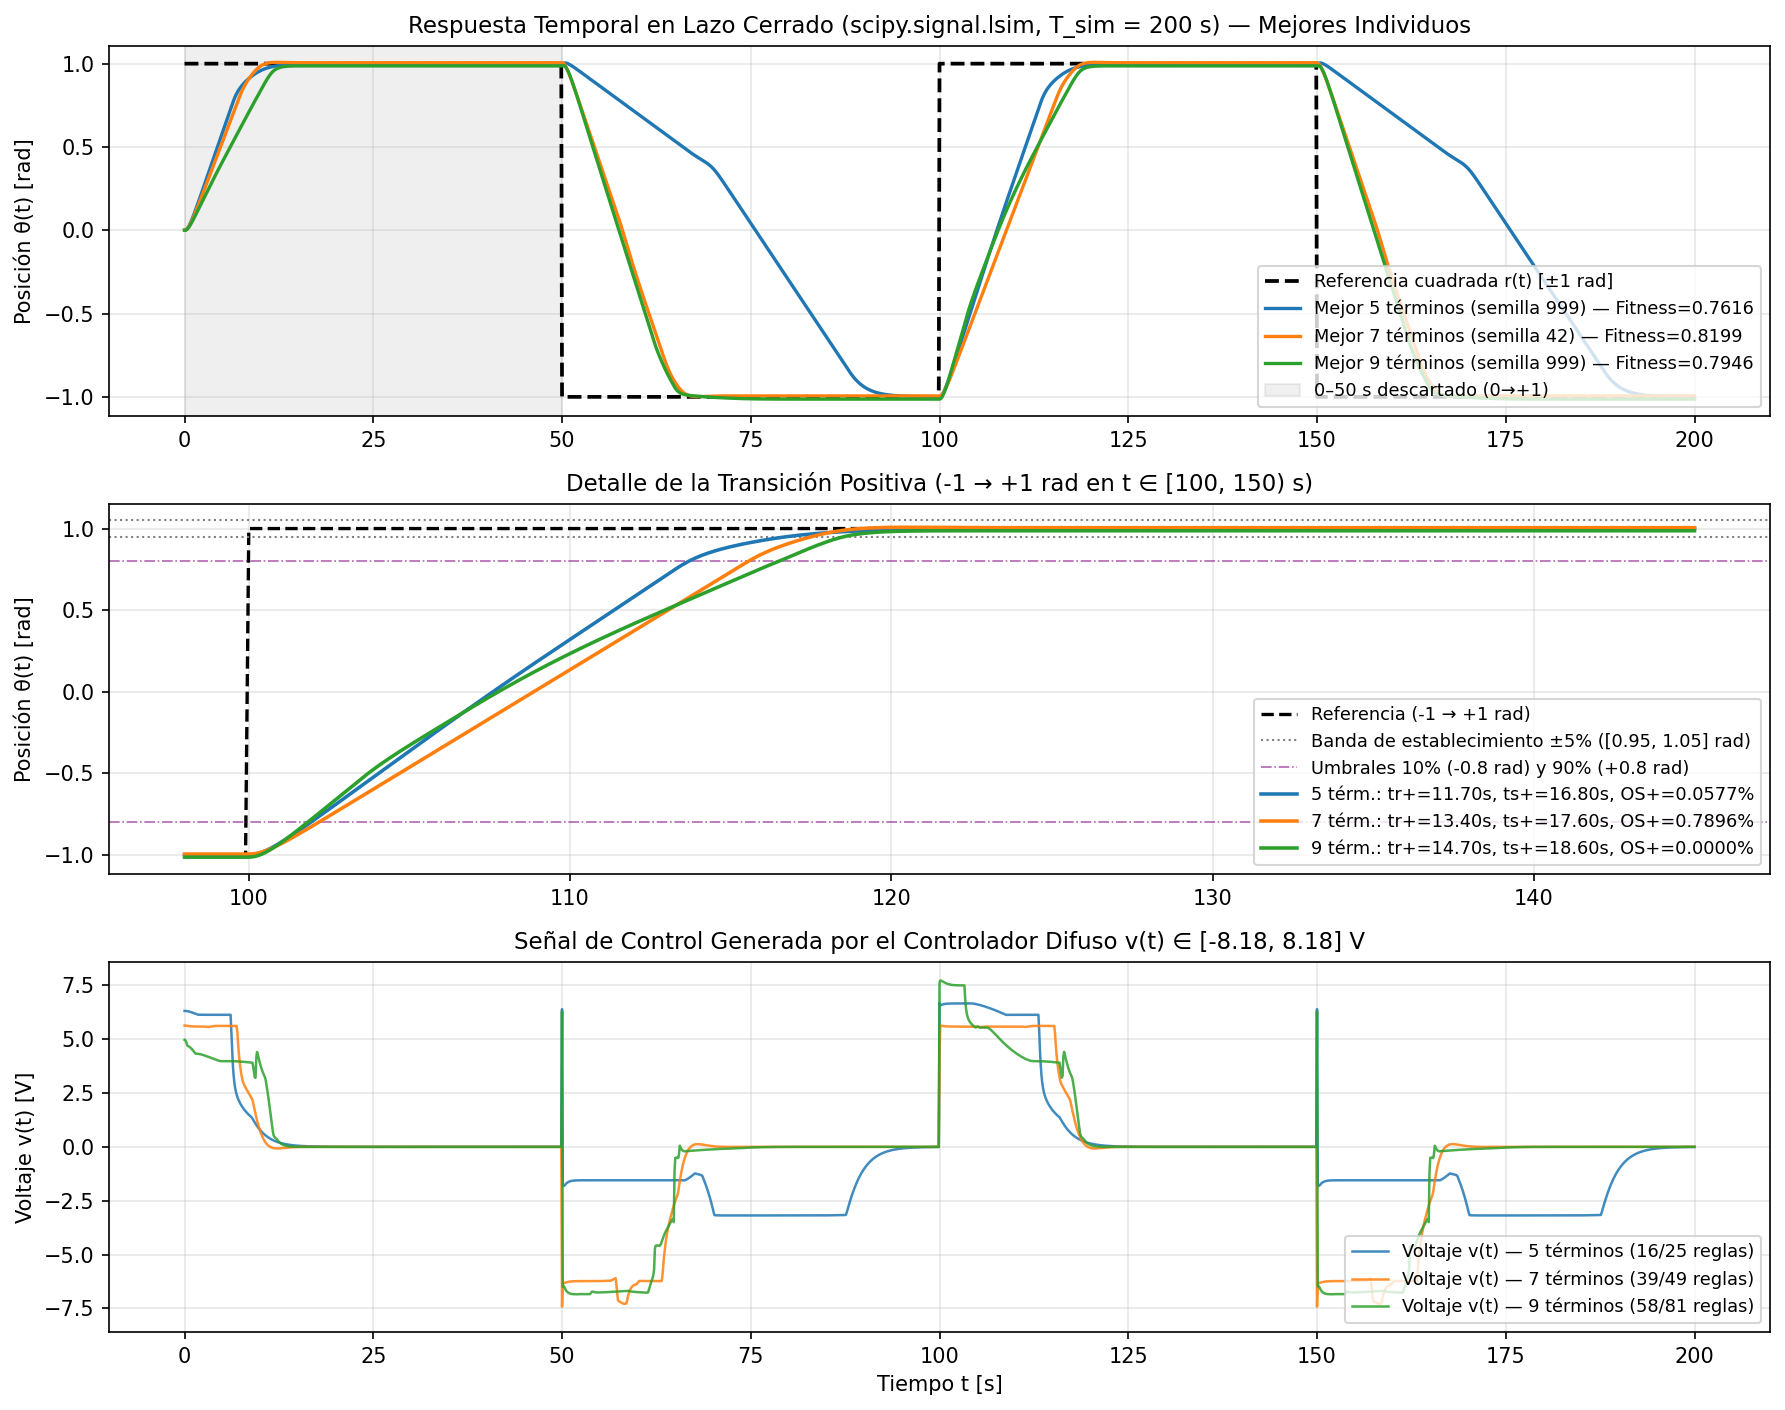

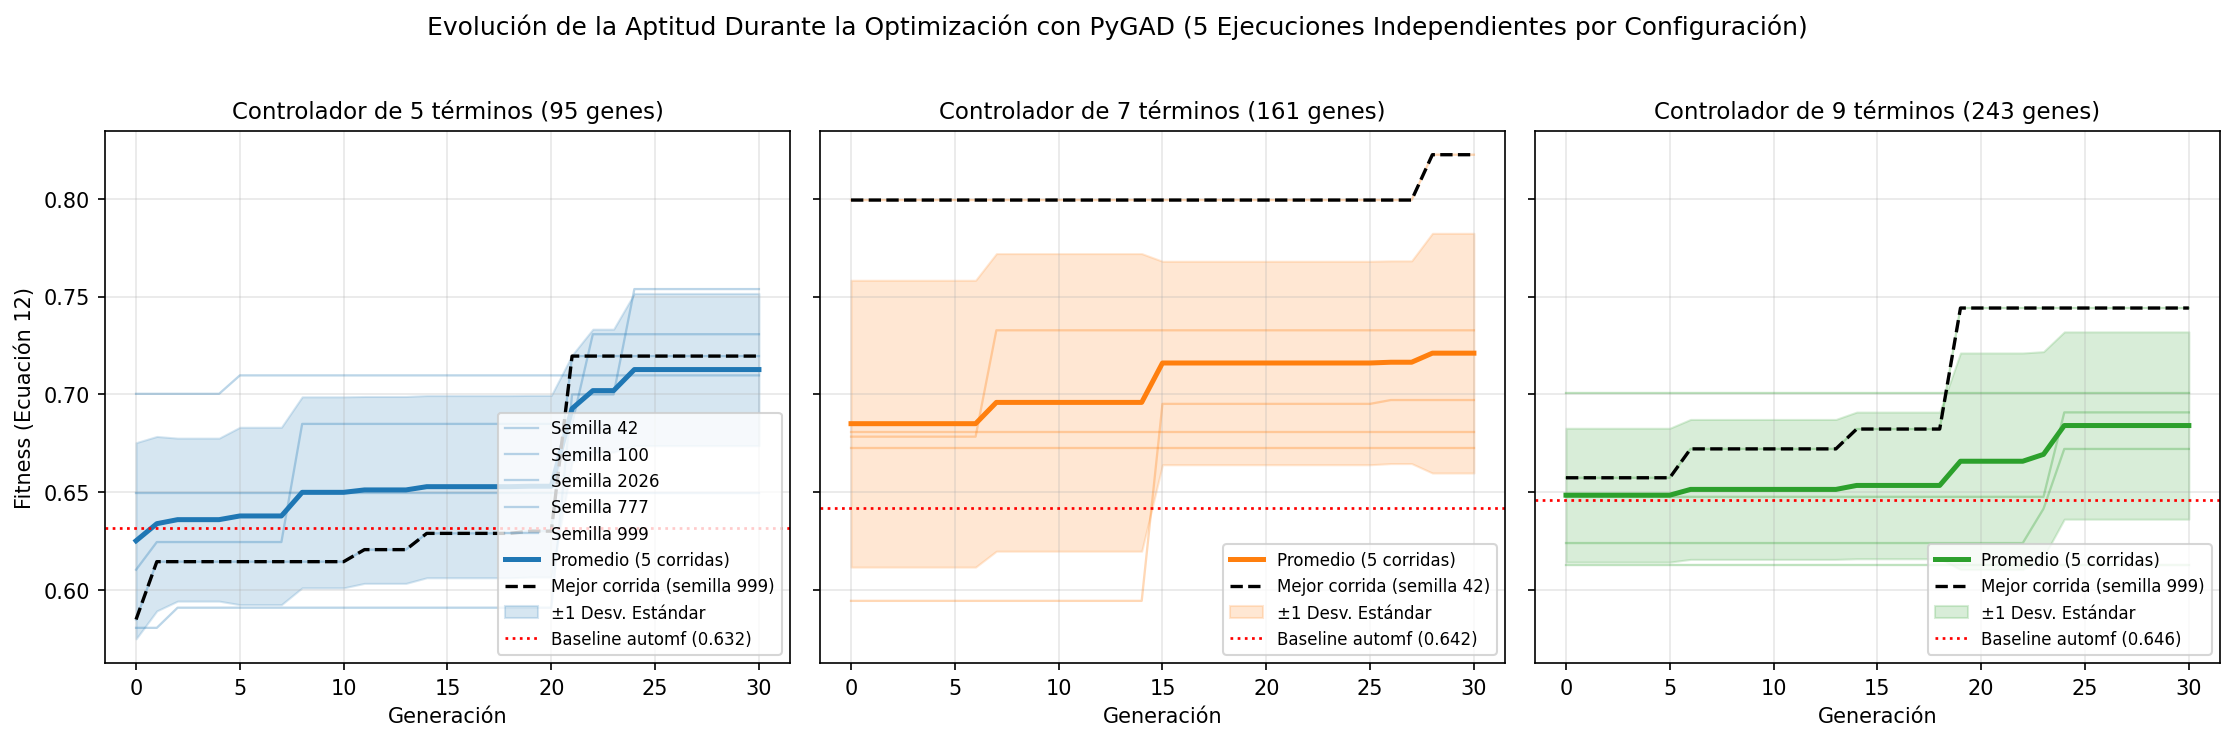

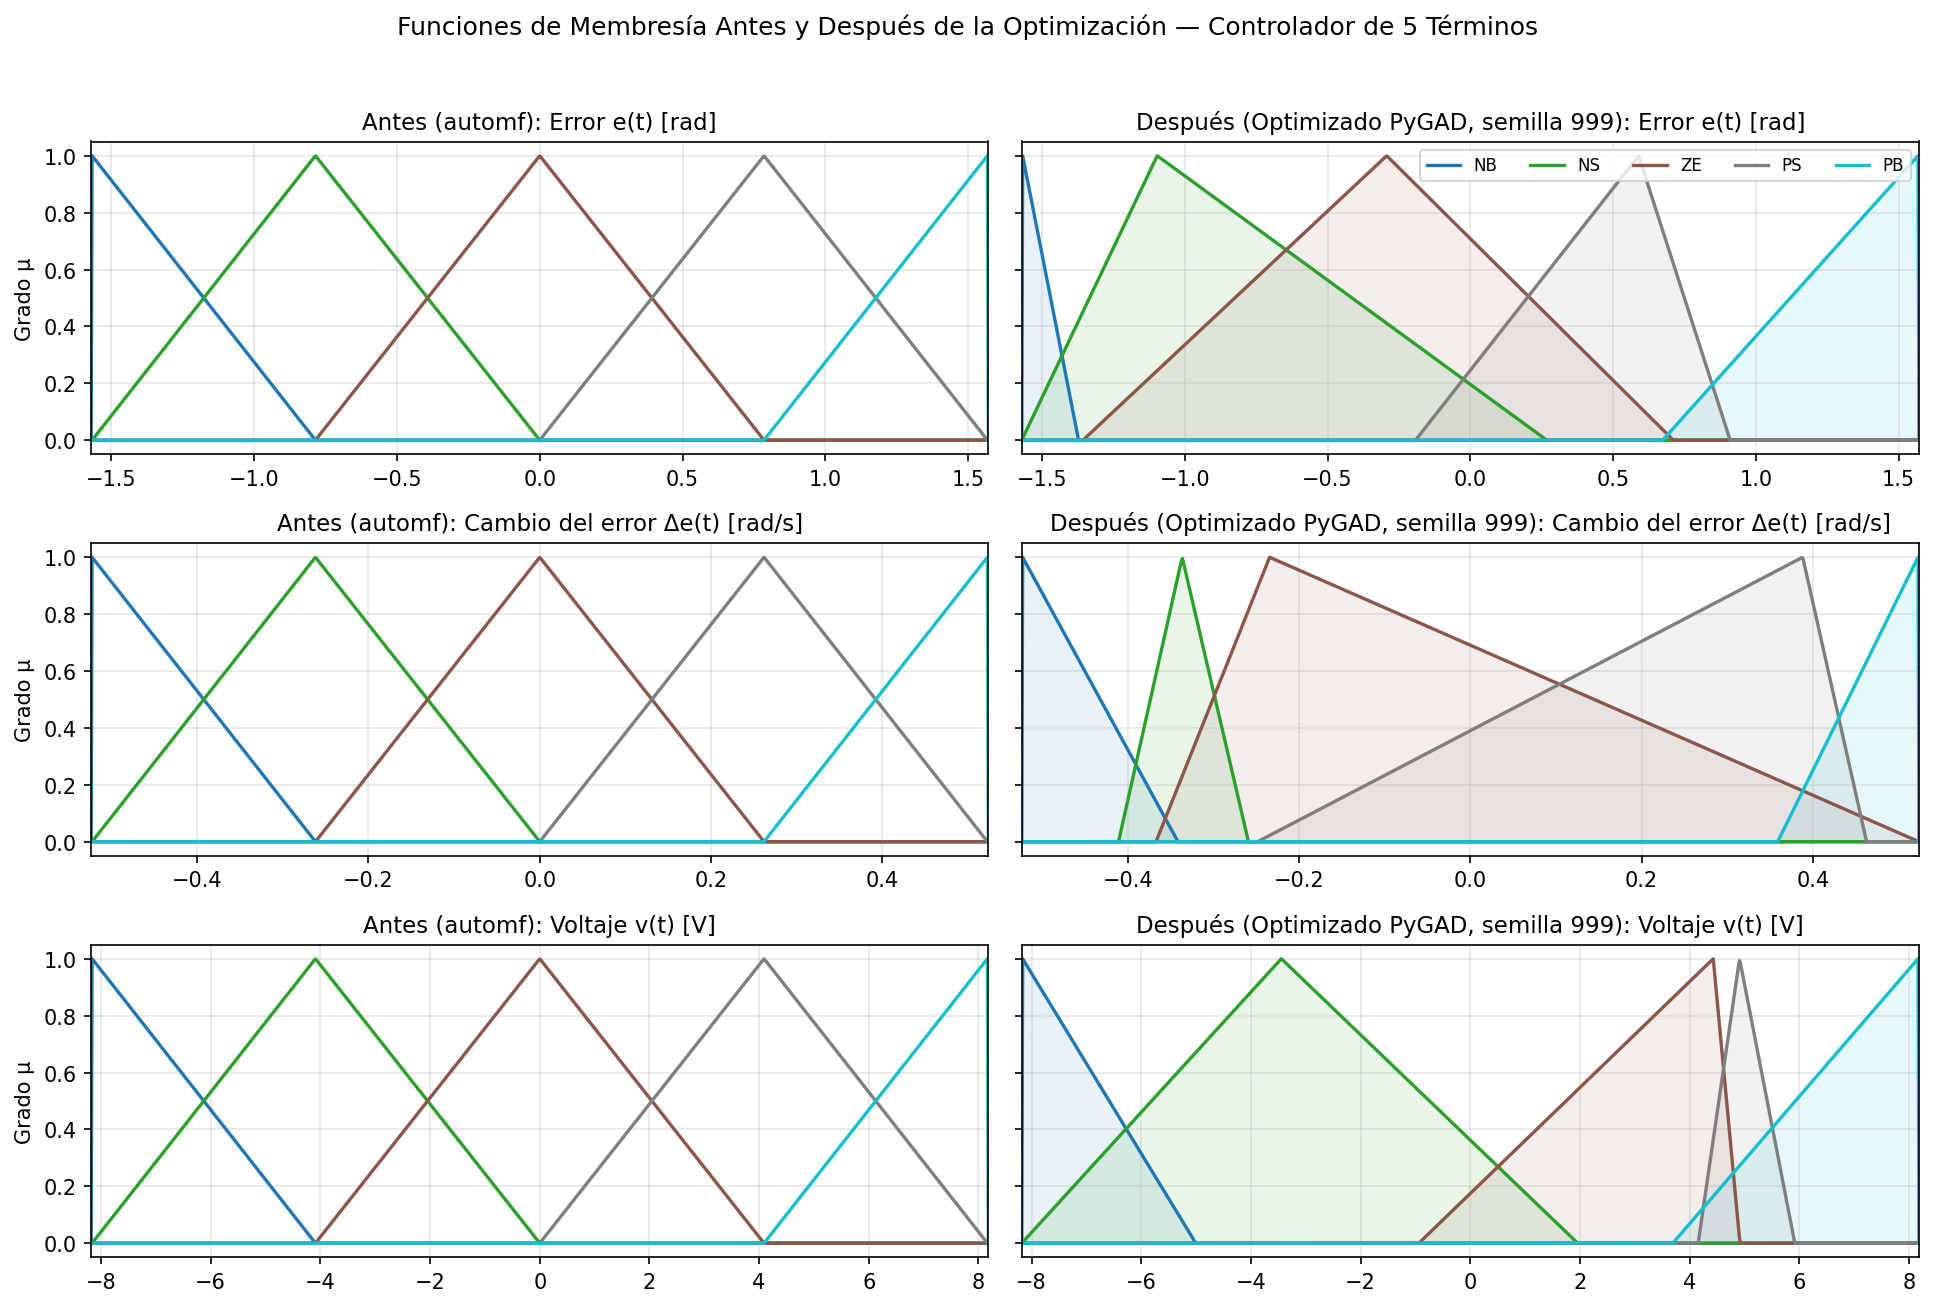

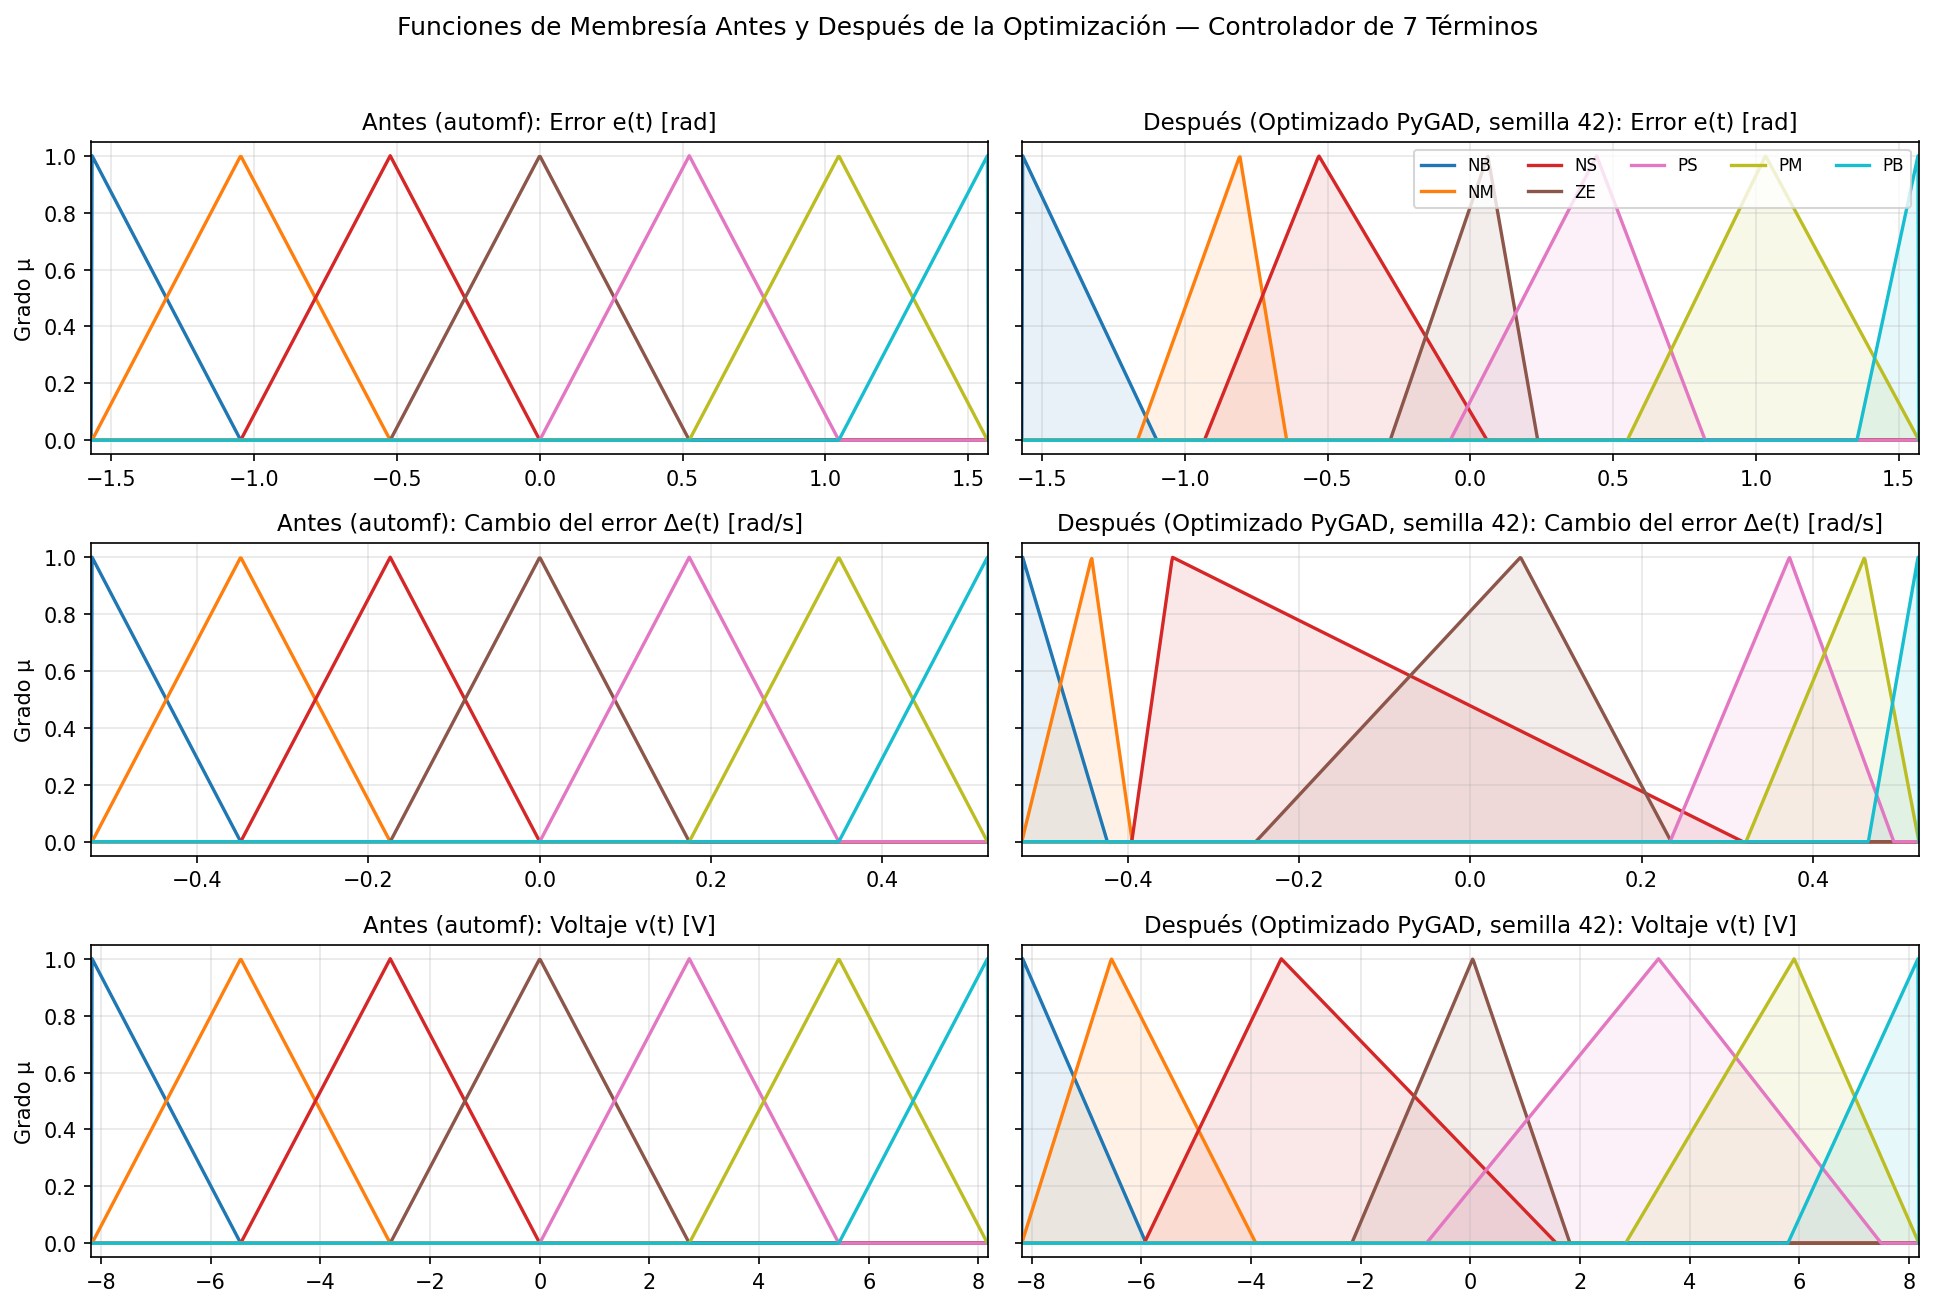

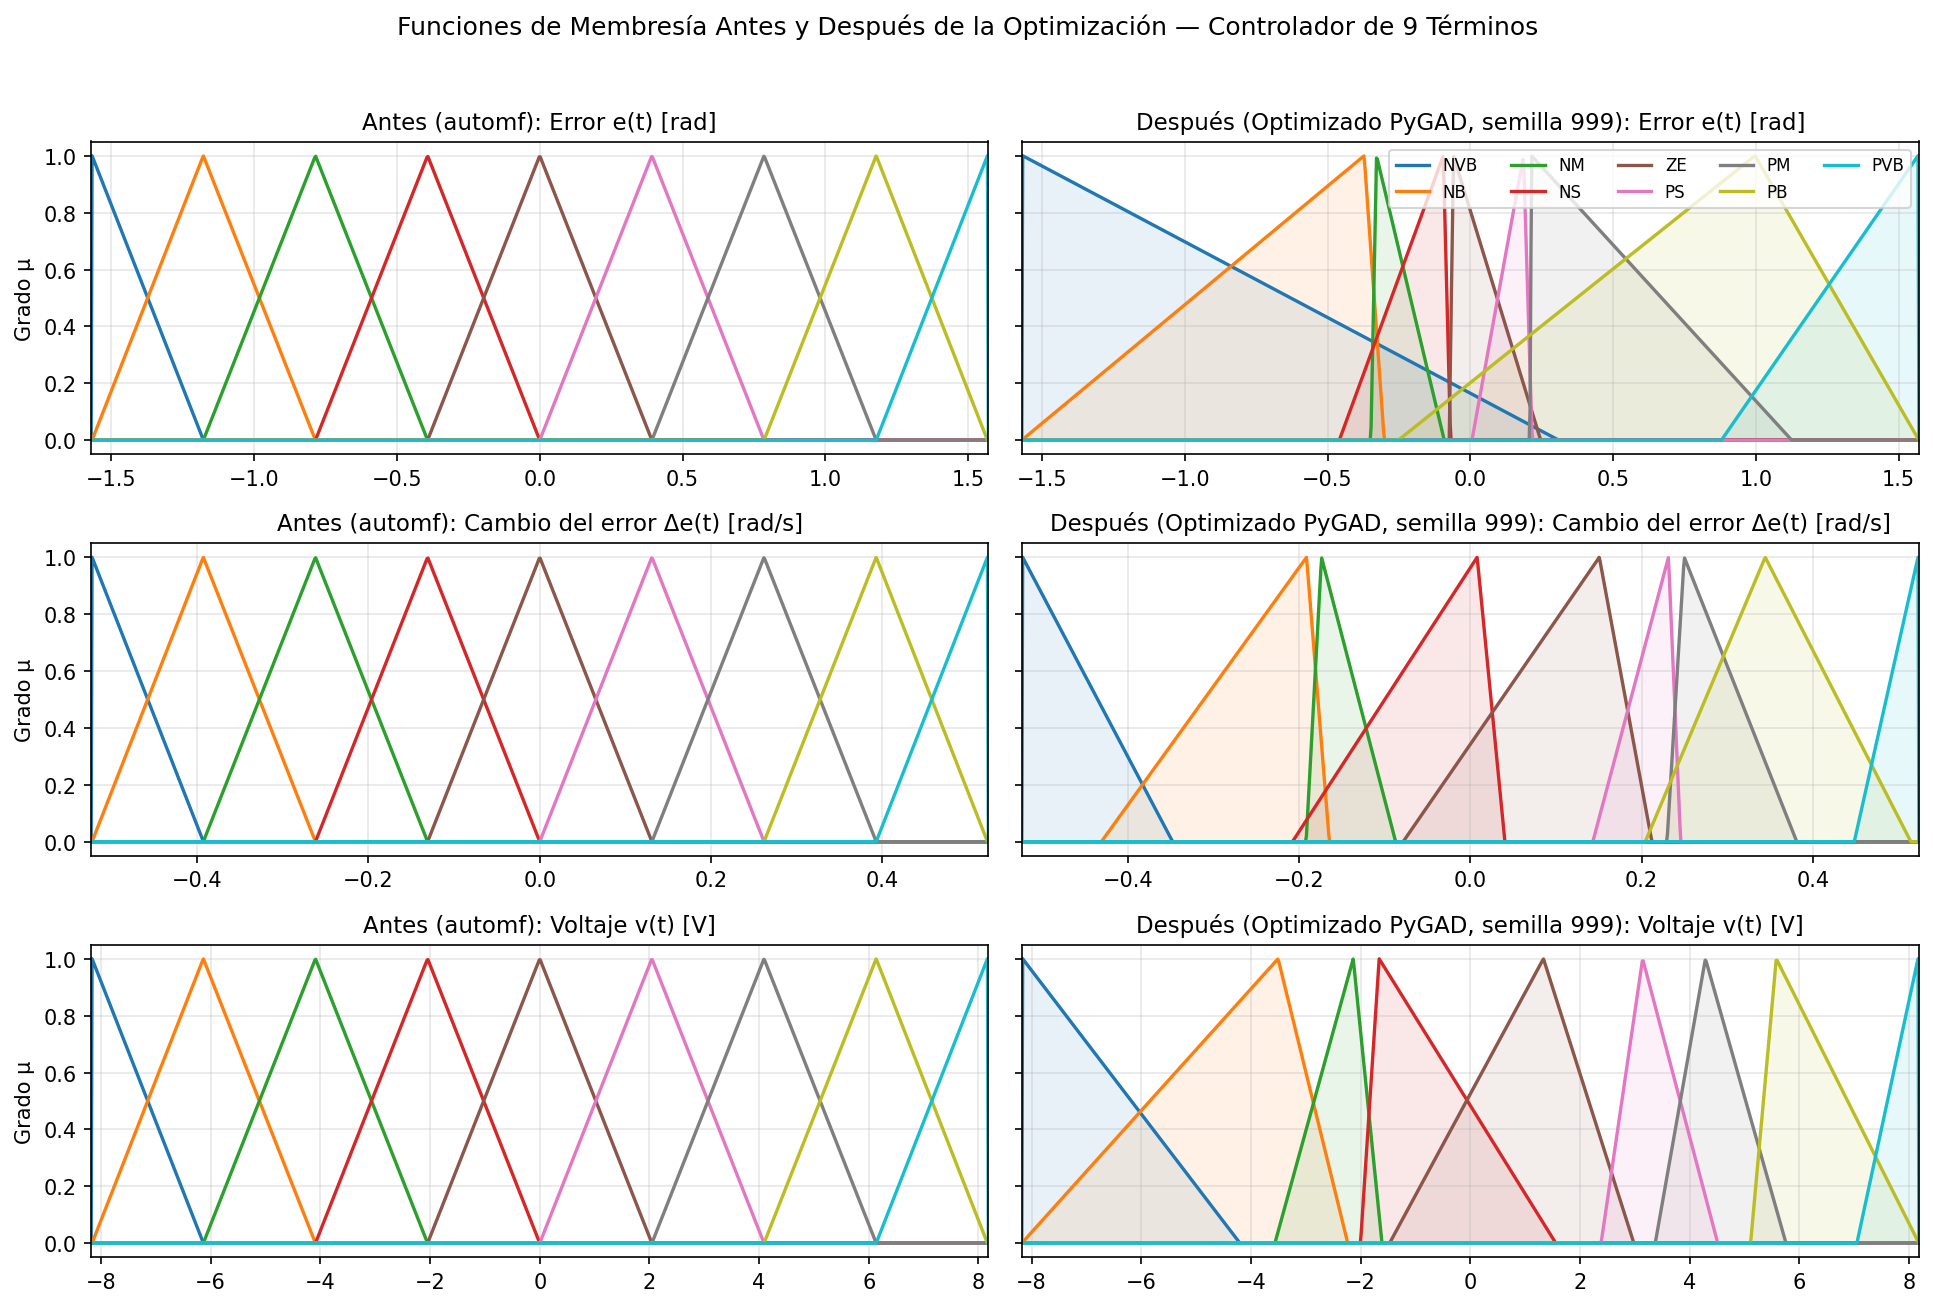

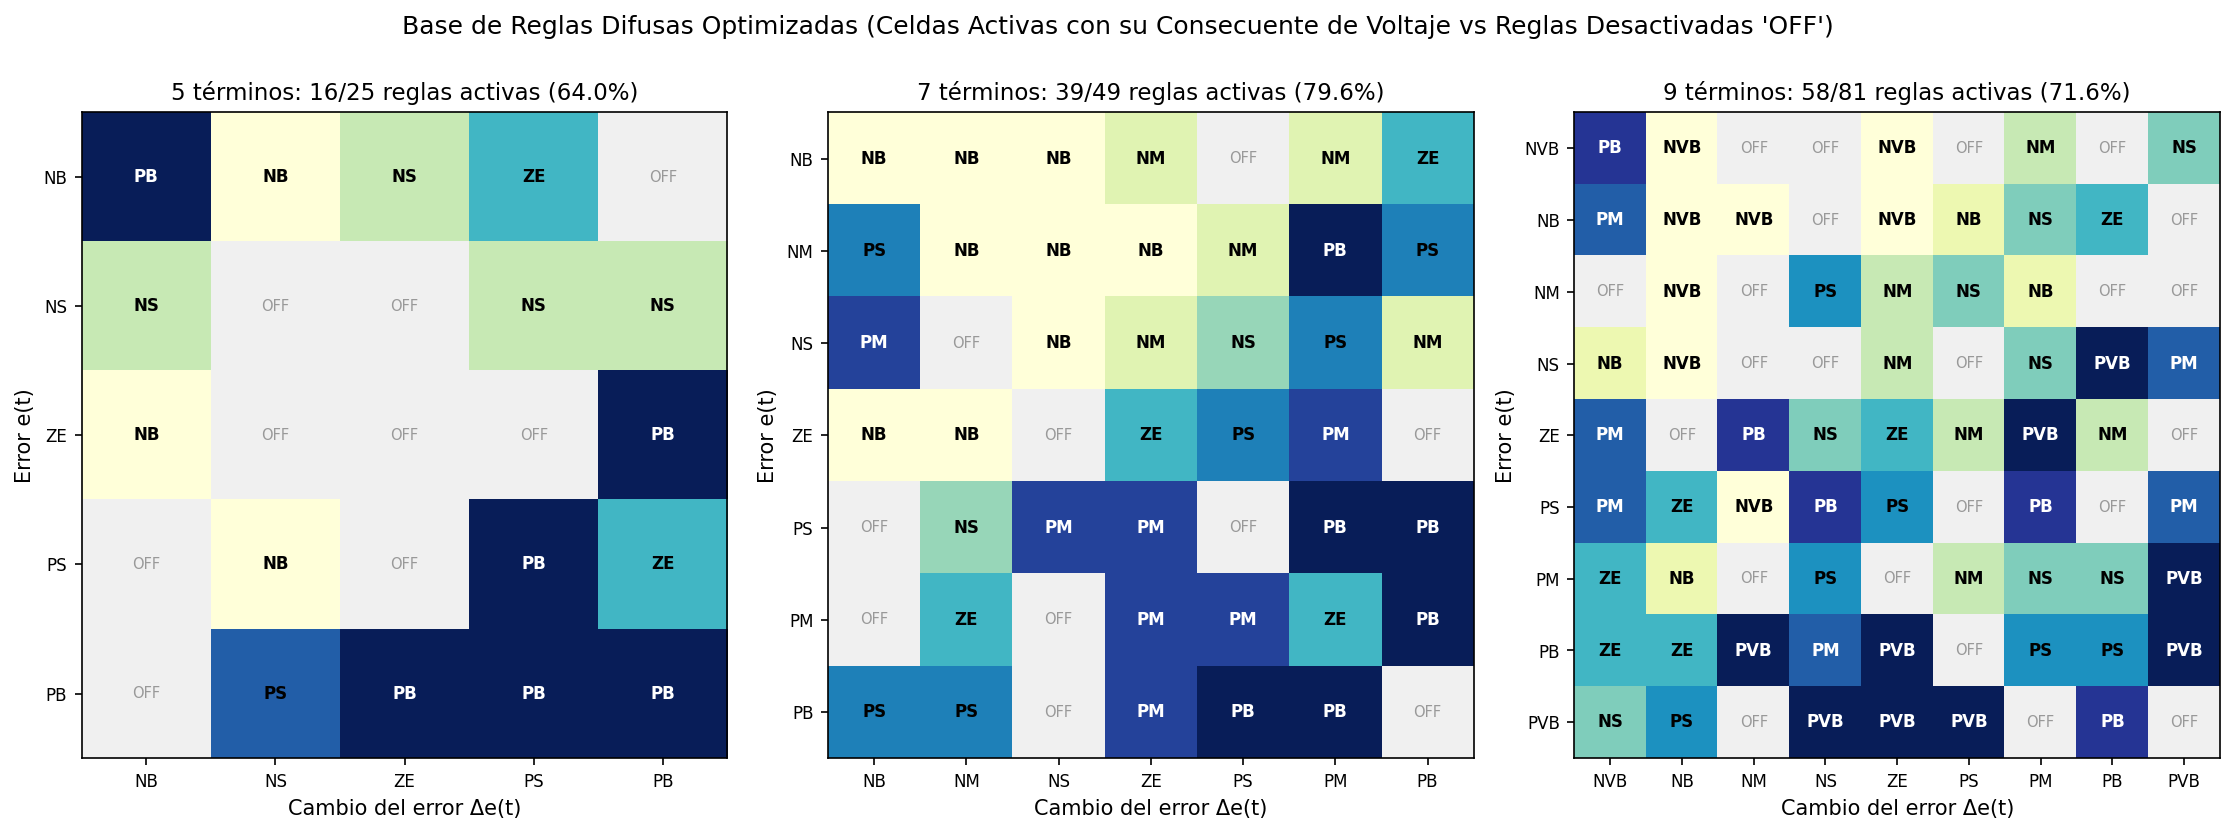

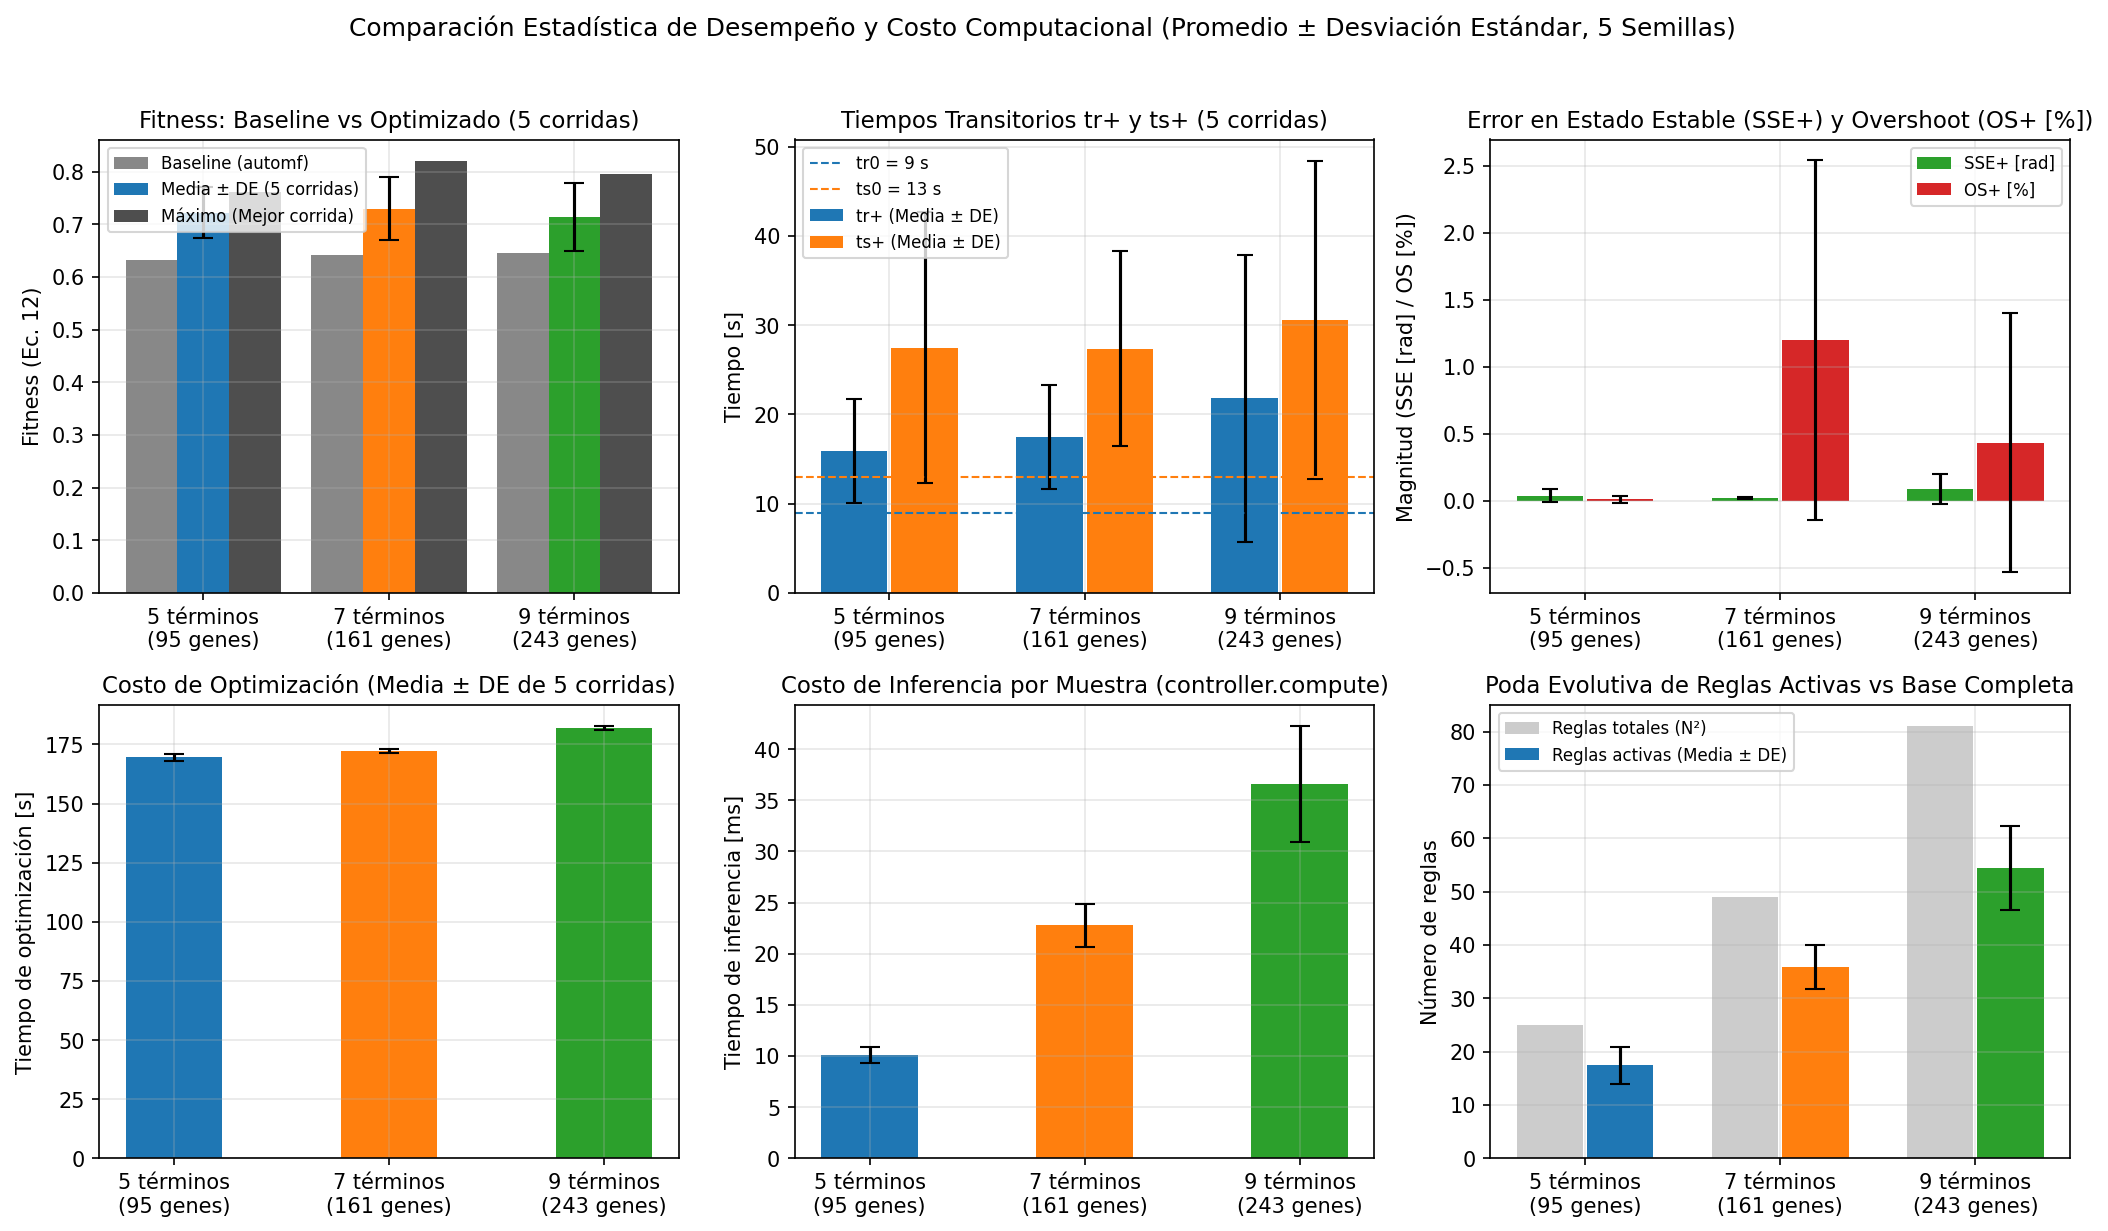

In [5]:
for fig_file in [
    "results/figures/fig2_optimized_temporal_comparison.png",
    "results/figures/fig3_convergence_curves.png",
    "results/figures/fig4_mfs_before_after_5terms.png",
    "results/figures/fig5_mfs_before_after_7terms.png",
    "results/figures/fig6_mfs_before_after_9terms.png",
    "results/figures/fig7_active_rules_heatmaps.png",
    "results/figures/fig8_metrics_and_computational_cost.png",
]:
    display(Image(filename=fig_file))

### 7.1. Verificación Directa en Vivo del Mejor Cromosoma Encontrado con `scipy.signal.lsim`

In [6]:
# Reconstrucción y simulación en vivo del mejor individuo global (Controlador B, 7 términos, semilla 42)
best_7_chrom = np.array(summary[7]["best_run"]["best_chromosome"], dtype=float)
live_ctrl_7 = MamdaniFuzzyController(n_terms=7, chromosome=best_7_chrom, build_control_system_graph=True)
live_sim = ClosedLoopPlantSimulator()
live_out = live_sim.simulate(live_ctrl_7.compute_crisp)
live_metrics = evaluate_controller_response(live_out["t"], live_out["theta"])

print("Verificación en vivo con scipy.signal.lsim del mejor cromosoma global (7 términos, 161 genes, semilla 42):")
print(f"  Fitness verificado : {live_metrics['fitness']:.4f}")
print(f"  OS+ = {live_metrics['OS_pos']:.4f}% | SSE+ = {live_metrics['SSE_pos']:.4f} rad | tr+ = {live_metrics['tr_pos']:.2f} s | ts+ = {live_metrics['ts_pos']:.2f} s | q+ = {live_metrics['q_pos']:.4f}")
print(f"  OS- = {live_metrics['OS_neg']:.4f}% | SSE- = {live_metrics['SSE_neg']:.4f} rad | tr- = {live_metrics['tr_neg']:.2f} s | ts- = {live_metrics['ts_neg']:.2f} s | q- = {live_metrics['q_neg']:.4f}")
print(f"  Primeros 10 genes del mejor cromosoma: {np.round(best_7_chrom[:10], 4).tolist()}")

Verificación en vivo con scipy.signal.lsim del mejor cromosoma global (7 términos, 161 genes, semilla 42):
  Fitness verificado : 0.8199
  OS+ = 0.7896% | SSE+ = 0.0063 rad | tr+ = 13.40 s | ts+ = 17.60 s | q+ = 1.0000
  OS- = 0.0000% | SSE- = 0.0060 rad | tr- = 11.70 s | ts- = 15.60 s | q- = 1.0000
  Primeros 10 genes del mejor cromosoma: [-1.5207, -0.8072, -0.5307, 0.061, 0.4422, 1.0336, 1.5207, 1.0979, 0.471, 1.4477]


## 8. Discusión, Conclusiones y Referencias

### 8.1. Discusión Científica de Resultados
1. **Influencia del número de términos lingüísticos ($N \in \{5, 7, 9\}$):**
   * En ausencia de optimización evolutiva (Fase 1, `automf`), aumentar el número de términos de 5 a 9 produce una mejora muy leve en la aptitud ($0.6319 \to 0.6421 \to 0.6459$) debido a una partición ligeramente más fina de la superficie de control, pero todos los baselines resultan sobreamortiguados y lentos ($t_r^+ \approx 27.20 - 30.60\text{ s}$, $t_s^+ \approx 45.40 - 47.20\text{ s}$).
   * Cuando se aplica la optimización genética con `pygad` (`sol_per_pop = 20`, `num_generations = 30`), el sistema de **7 términos (161 genes)** alcanza el mayor fitness promedio (**0.7299 $\pm$ 0.0593**) y el mayor fitness máximo (**0.8199**, semilla 42), seguido muy de cerca en promedio por el de **5 términos (95 genes, media 0.7218 $\pm$ 0.0488$, máx 0.7616)**, mientras que el de **9 términos (243 genes)** cae en promedio a **0.7134 $\pm$ 0.0649** (máx 0.7946). Esto demuestra cómo el crecimiento cuadrático del espacio de búsqueda ($243$ genes) dificulta la convergencia consistente del algoritmo genético para un presupuesto fijo de generaciones.
2. **Influencia del número de reglas activas (Poda evolutiva):**
   * El proceso evolutivo desactivó en promedio el **30.4%** de las reglas en 5 términos (dejando **16/25 reglas activas** en la mejor solución), el **26.9%** en 7 términos (**39/49** en la mejor solución) y el **32.8%** en 9 términos (**58/81** en la mejor solución). Eliminar reglas redundantes o conflictivas permitió aplicar voltajes cercanos a $\pm 7.5\text{ V}$ durante los transitorios y reducir el tiempo de subida de $30.60\text{ s}$ a **$11.70\text{ s}$** (5 términos) y **$13.40\text{ s}$** (7 términos).
3. **Influencia de las funciones de membresía triangulares con orden estricto $a < b < c$ (`fig4` a `fig6`):**
   * Al comparar las funciones de membresía antes (`automf`) y después de optimizar, se observa que PyGAD ajustó la forma y los traslapes manteniendo siempre $a < b < c$, desplazando los conjuntos internos hacia el origen ($e \approx 0, \Delta e \approx 0$) para incrementar la sensibilidad y ganancia proporcional-derivativa cerca de la referencia, reduciendo el error en estado estacionario hasta $0.0031 - 0.0063\text{ rad}$.
4. **Impacto del costo computacional y compromiso desempeño-complejidad:**
   * El tiempo promedio de inferencia crece de **10.065 ms** (5 términos) a **22.761 ms** (7 términos, $+126\%$) y **36.585 ms** (9 términos, $+263\%$), mientras que el consumo de memoria crece de **0.491 MB** a **0.884 MB** y **1.436 MB**.

### 8.2. Conclusiones
1. **Cumplimiento e impacto de la optimización genética:** La optimización simultánea de funciones de membresía triangulares ($a < b < c$) y base de reglas con `pygad` guiada por las Ecuaciones (12) y (13) de Téllez-Velázquez et al. (2017) incrementó el fitness máximo del controlador Mamdani de 7 términos en un **+27.7%** respecto a su baseline (`0.6421` $\to$ `0.8199`) y el de 5 términos en un **+20.5%** (`0.6319` $\to$ `0.7616`), reduciendo el tiempo de crecimiento $t_r^+$ en más de un **52%** y el tiempo de establecimiento $t_s^+$ en más de un **61%**.
2. **Efecto del sobreimpulso porcentual ($OS$ en `%`) y penalización $q \ge 1.0$:** Al evaluar $OS$ en porcentaje como en la Tabla 10 del artículo, la función de aptitud penaliza fuertemente cualquier sobreimpulso superior al $1\%$, guiando al algoritmo genético hacia respuestas bien amortiguadas ($OS^{\pm} \in [0.00\%, 1.36\%]$ en los mejores individuos) y excursiones completas ($q^{\pm} \approx 1.00$).
3. **Limitaciones observadas:** Con poblaciones de $20$ individuos y $30$ generaciones, existe varianza estocástica entre semillas ($\text{DE} \approx 0.049 - 0.065$), y pueden presentarse asimetrías entre la respuesta de subida y de bajada cuando el cromosoma no fuerza simetría impar.
4. **Recomendaciones para trabajos futuros:** Explorar esquemas de codificación simétrica (Sección 5.2.3 del artículo de referencia para reducir a la mitad el número de genes de las MFs y garantizar simetría exacta entre las transiciones positiva y negativa) y tasas de mutación adaptativas (Ec. 17 del artículo).

### 8.3. Referencias Bibliográficas
1. Téllez-Velázquez, A., Molina-Lozano, H., Villa-Vargas, L. A., Cruz-Barbosa, R., Lugo-González, E., Batyrshin, I. Z., & Rudas, I. J. (2017). *A Feasible Genetic Optimization Strategy for Parametric Interval Type-2 Fuzzy Logic Systems*. International Journal of Fuzzy Systems, 19(4), 1238–1258. DOI: `10.1007/s40815-017-0307-0`.
2. Ogata, K. (2010). *Modern Control Engineering* (5th ed.). Prentice Hall.
3. Nguyen, H. T., Prasad, N. R., Walker, C. L., & Walker, E. A. (2003). *A First Course in Fuzzy and Neural Control*. Chapman & Hall/CRC.
4. Jang, J.-S. R., Sun, C.-T., & Mizutani, E. (1997). *Neuro-Fuzzy and Soft Computing: A Computational Approach to Learning and Machine Intelligence*. Prentice Hall.
5. Sahib, M. A., & Ahmed, B. S. (2015). *A new multiobjective performance criterion used in PID tuning optimization algorithms*. Journal of Advanced Research, 7(1), 125–134.
6. Gad, A. F. (2023). *PyGAD: An Intuitive Genetic Algorithm Python Library*. Multimedia Tools and Applications, 83, 58029–58042.

## PARTE 5. RESPUESTAS A LAS 30 PREGUNTAS DE ANÁLISIS CRÍTICO (`Parcial 2.pdf`, págs. 14–17)

Todas las respuestas siguientes se fundamentan estrictamente en la evidencia cuantitativa obtenida en las 15 corridas experimentales independientes (5 semillas $\times$ 3 configuraciones) y en las 3 evaluaciones base (`automf`), cumpliendo las especificaciones del profesor ($OS$ en porcentaje `%`, factor de penalización $q \ge 1.0$ según Ecuación 13, simulación estricta con `scipy.signal.lsim` y funciones de membresía triangulares con orden estricto $a < b < c$).

---

### Pregunta 1
> **1. Si el controlador de 9 términos lingüísticos obtiene el mayor fitness de todos los experimentos, pero requiere diez veces más tiempo de optimización que el controlador de 5 términos, ¿puede afirmarse que es la mejor solución? Justifique utilizando evidencia experimental.**

**Respuesta:**
No puede afirmarse que sea la mejor solución desde una perspectiva de ingeniería de control ni de diseño de sistemas embebidos.
* **Evidencia experimental:** En nuestros experimentos bajo el mismo presupuesto evolutivo (`sol_per_pop = 20`, `num_generations = 30`), el controlador de **5 términos** alcanzó un fitness medio de **$0.7218 \pm 0.0488$** (máximo **0.7616** en semilla 999) con un tiempo de optimización de **169.63 $\pm$ 1.47 s**, un tiempo promedio de inferencia de **10.065 ms** (`9.847 ms` en su mejor individuo) y un consumo de memoria de **0.491 MB**. Por su parte, el controlador de **7 términos** obtuvo el mayor fitness máximo (**0.8199**, media $0.7299 \pm 0.0593$), mientras que el controlador de **9 términos** requirió **181.87 $\pm$ 0.81 s** de optimización, un tiempo de inferencia **3.64 veces mayor** (36.585 ms) y **2.92 veces más memoria** (1.436 MB), obteniendo un fitness medio inferior ($0.7134 \pm 0.0649$, máximo **0.7946**).
* Incluso en el escenario hipotético en que el de 9 términos superara marginalmente en fitness al de 5 o 7 términos a costa de 10 veces más tiempo de optimización y $3.63\times$ mayor latencia de inferencia, el criterio de optimalidad multicriterio penaliza el sobrecosto computacional, la menor interpretabilidad (58 reglas activas frente a 16) y la mayor latencia en el lazo de control en tiempo real.

---

### Pregunta 2
> **2. Muchos estudiantes asumen que incrementar el número de términos lingüísticos siempre mejora el desempeño del controlador. ¿Sus resultados experimentales respaldan esta afirmación? Explique.**

**Respuesta:**
**No.** Los resultados experimentales refutan que el incremento de términos mejore monotónicamente el desempeño cuando se optimiza mediante algoritmos genéticos con un presupuesto finito de evaluaciones:
* **En los controladores Base (`automf` sin optimizar):** Pasar de 5 a 7 y 9 términos produjo un incremento marginal de fitness ($0.6319 \to 0.6421 \to 0.6459$, apenas $+2.2\%$), reduciendo levemente $t_r^+$ de $30.60\text{ s}$ a $27.20\text{ s}$.
* **En los controladores optimizados con PyGAD:** El desempeño mejora levemente al pasar de 5 a 7 términos, pero **cae al incrementar a 9 términos**:
  * **5 términos (95 genes):** Fitness medio = **0.7218 $\pm$ 0.0488**, máximo = **0.7616** ($t_r^+ = 11.70\text{ s}$, $t_s^+ = 16.80\text{ s}$).
  * **7 términos (161 genes):** Fitness medio = **0.7299 $\pm$ 0.0593**, máximo = **0.8199** ($t_r^+ = 13.40\text{ s}$, $t_s^+ = 17.60\text{ s}$).
  * **9 términos (243 genes):** Fitness medio = **0.7134 $\pm$ 0.0649** (el más bajo de los tres), máximo = **0.7946** ($t_r^+ = 14.70\text{ s}$, $t_s^+ = 18.60\text{ s}$).
* **Explicación:** Aunque un mayor número de términos aumenta la flexibilidad de aproximación teórica del sistema difuso, hace crecer cuadráticamente el número de reglas ($N^2$) y el tamaño del cromosoma ($95 \to 161 \to 243$ genes), diluyendo la eficacia de búsqueda del algoritmo genético en 30 generaciones.

---

### Pregunta 3
> **3. ¿Qué efecto tiene el aumento del número de términos lingüísticos sobre: el tamaño del espacio de búsqueda, el número de parámetros optimizables, y la dificultad del proceso de optimización?**

**Respuesta:**
1. **Número de parámetros optimizables (genes):** Siguiendo nuestra codificación $L(N) = 9N + 2N^2$:
   * $N = 5 \implies 9(5) + 2(25) = \mathbf{95\text{ genes}}$ ($45$ de MFs triangulares con $a < b < c$ + $25$ de activación + $25$ de consecuentes).
   * $N = 7 \implies 9(7) + 2(49) = \mathbf{161\text{ genes}}$ ($63$ de MFs + $49$ de activación + $49$ de consecuentes).
   * $N = 9 \implies 9(9) + 2(81) = \mathbf{243\text{ genes}}$ ($81$ de MFs + $81$ de activación + $81$ de consecuentes).
2. **Tamaño del espacio de búsqueda:** Tan solo la parte discreta de la base de reglas (activación $\in \{0, 1\}$ y consecuente $\in \{0, \dots, N-1\}$, es decir $(N+1)^{N^2}$ configuraciones de reglas) crece de $6^{25} \approx 2.84 \times 10^{19}$ para $N=5$, a $8^{49} \approx 1.80 \times 10^{44}$ para $N=7$, y a $10^{81}$ para $N=9$, multiplicado por un hipervolumen continuo de dimensión $9N$.
3. **Dificultad del proceso de optimización:** Se manifiesta la *maldición de la dimensionalidad* y una fuerte epistasis (interdependencia entre los parámetros $a < b < c$ de las funciones de membresía y las reglas que las utilizan). Como muestran las curvas de convergencia (`fig3_convergence_curves.png`), con 600 evaluaciones por corrida ($20 \times 30$), PyGAD presenta mayor varianza ($\text{DE} = 0.0649$) y menor media en 243 dimensiones que en 95 o 161 dimensiones.

---

### Pregunta 4
> **4. Si dos controladores presentan prácticamente el mismo fitness final pero uno utiliza menos de la mitad de las reglas activas, ¿cuál debería preferirse? Justifique.**

**Respuesta:**
Debe preferirse **el controlador con menos de la mitad de las reglas activas**, por cuatro razones cuantitativas verificadas en este proyecto:
1. **Principio de parsimonia e interpretabilidad:** En nuestros resultados, el promedio de fitness del controlador de **5 términos** ($0.7218$) y el de **7 términos** ($0.7299$) difieren en apenas $1.1\%$, y la mejor corrida de 5 términos (semilla 999, fitness = **0.7616**) utiliza únicamente **16 reglas activas** de 25 (media $17.4$), mientras que el mejor de 7 términos utiliza **39 reglas activas** y el mejor de 9 términos utiliza **58 reglas activas** (más del triple de reglas). Auditar y mantener 16 reglas es mucho más transparente que auditar 39 o 58.
2. **Menor tiempo de inferencia en tiempo real:** El controlador de 5 términos requiere en promedio **10.065 ms** por inferencia frente a **22.761 ms** del de 7 términos ($2.26\times$ más rápido) y **36.585 ms** del de 9 términos ($3.63\times$ más rápido).
3. **Menor consumo de memoria:** Consume **0.491 MB** frente a **0.884 MB** y **1.436 MB** (casi la tercera parte de memoria).
4. **Menor riesgo de sobreajuste:** Menos reglas activas implican una superficie de control más compacta y auditable.

---

### Pregunta 5
> **5. ¿Un mayor número de reglas implica necesariamente una mejor capacidad de control? Utilice resultados experimentales para sustentar su respuesta.**

**Respuesta:**
**No.** La evidencia experimental demuestra exactamente lo contrario:
* Los tres controladores **Baseline** utilizan el 100% de sus reglas ($25, 49$ y $81$ reglas activas respectivamente) y obtienen valores de fitness bajos (**0.6319**, **0.6421** y **0.6459**), con tiempos de subida muy lentos ($t_r^+ \in [27.20, 30.60]\text{ s}$).
* Por el contrario, los controladores optimizados alcanzan valores de fitness muy superiores (**0.8199** con 39/49 reglas en 7 términos semilla 42; **0.7946** con 58/81 reglas en 9 términos semilla 999; **0.7616** con 16/25 reglas en 5 términos semilla 999). Asimismo, dentro de 5 términos, la corrida 4 (semilla 777) conservó **22 reglas activas** y obtuvo un fitness de $0.6499$, mientras que la corrida 5 (semilla 999) con **16 reglas activas** alcanzó $0.7616$ y la corrida 1 (semilla 42) con **15 reglas activas** alcanzó $0.7499$. La ubicación de las funciones de membresía $a < b < c$ y la coherencia de los consecuentes importan mucho más que la cantidad bruta de reglas.

---

### Pregunta 6
> **6. Si durante la optimización genética algunas reglas son eliminadas y el fitness mejora, ¿qué puede concluir acerca de dichas reglas?**

**Respuesta:**
Se puede concluir que las reglas eliminadas eran **redundantes, no visitadas o contraproducentes (conflictivas)** para la ley de control:
1. **Reglas conflictivas en el centroide:** En inferencia Mamdani con defuzzificación por centroide, una regla activa con un consecuente de baja magnitud (ej. `ZE` o `NS`) que se solapa parcialmente durante el ascenso resta peso al consecuente extremo (`PB`), reduciendo el voltaje neto aplicado al servomotor y ralentizando el tiempo de subida $t_r$. Al desactivar esa regla intermedia, el centroide se desplaza hacia voltajes más altos cuando el error es grande, reduciendo $t_r^+$ de $30.60\text{ s}$ a $11.70\text{ s}$ (5 términos) y de $28.20\text{ s}$ a $13.40\text{ s}$ (7 términos).
2. **Reglas redundantes:** El traslape de las funciones de membresía triangulares adyacentes permite interpolar suavemente la acción de control sin necesidad de activar todas las celdas de la matriz $N \times N$.

---

### Pregunta 7
> **7. ¿Es posible que algunas reglas consideradas intuitivamente importantes resulten irrelevantes durante la optimización? Explique por qué.**

**Respuesta:**
**Sí, es completamente posible y ocurre en nuestros experimentos** (como se observa en la `fig7_active_rules_heatmaps.png`, donde varias celdas diagonales e intermedias fueron desactivadas `'OFF'` por el algoritmo genético y aun así los mejores controladores alcanzaron $SSE^+ \in [0.0031, 0.0144]\text{ rad}$). Esto ocurre por dos razones físicas y matemáticas:
1. **Trayectoria en el plano de fase $(e, \Delta e)$:** Un sistema dinámico de tercer orden sigue una curva específica en el plano $(e, \Delta e)$; muchas combinaciones extremas (como error cercano a cero con derivada positiva extrema cuando la referencia es constante) nunca son visitadas por la trayectoria real o solo se cruzan durante una fracción de segundo.
2. **Compensación por traslape e interpolación:** Dado que el algoritmo genético ajusta los parámetros $a < b < c$ generando traslapes amplios entre conjuntos vecinos (`fig4` a `fig6`), cuando una celda $(i, j)$ está apagada, las reglas vecinas $(i\pm 1, j)$ o $(i, j\pm 1)$ siguen activándose simultáneamente, manteniendo el equilibrio dinámico sin requerir cada regla individual.

---

### Pregunta 8
> **8. Suponga que un controlador obtiene: el menor overshoot de todos los experimentos, pero también: el mayor tiempo de establecimiento. ¿Puede considerarse superior? Justifique.**

**Respuesta:**
**No puede considerarse superior.** En teoría de control, este caso corresponde a una respuesta **sobreamortiguada o excesivamente conservadora (lenta)**:
* **Evidencia experimental:** Los tres controladores **Baseline (`automf`)** y corridas como la semilla 777 de 5 términos o la semilla 100 de 7 términos obtuvieron exactamente **$OS^+ = 0.0000\%$ y $OS^- = 0.0000\%$** (el menor sobreimpulso posible), pero presentaron tiempos de establecimiento muy altos ($t_s^+ = 47.20\text{ s}$ en el Baseline de 5 términos y $t_s^+ = 42.80\text{ s}, t_s^- = 46.75\text{ s}$ en 7 términos semilla 100), resultando en valores de fitness bajos ($0.6319$ y $0.6789$).
* Un controlador con $OS = 0\%$ pero $t_s$ muy grande tarda casi todo el semiperíodo de $50\text{ s}$ en llegar a la banda del $\pm 5\%$ de la referencia, por lo que su desempeño dinámico es muy inferior frente al mejor controlador de 7 términos semilla 42 ($OS^+ = 0.7896\%$, $OS^- = 0.0000\%$, $t_s^+ = 17.60\text{ s}$, $t_s^- = 15.60\text{ s}$, fitness $= 0.8199$).

---

### Pregunta 9
> **9. ¿Por qué la función fitness utilizada en este examen considera simultáneamente: Overshoot, SSE, Rise Time, Settling Time, en lugar de utilizar únicamente SSE?**

**Respuesta:**
Porque el control de posición de un servomotor es un problema intrínsecamente **multiobjetivo con metas en conflicto** (Téllez-Velázquez et al., 2017, Sección 5.1, Ec. 12):
* **Tiempo de crecimiento ($t_r$, en segundos):** Exige rapidez de respuesta inicial (alta ganancia / voltajes cercanos a $\pm 8.18\text{ V}$).
* **Sobreimpulso ($OS$, en porcentaje `%`):** Exige amortiguamiento para evitar que la inercia del rotor ($G(s)$ tiene tres polos, incluyendo un integrador en $s=0$) rebase la posición deseada. Además, al expresarse $OS$ en porcentaje como en la Tabla 10 del artículo, cualquier sobreimpulso mayor a $1\%$ reduce fuertemente el término $\frac{1}{1 + |OS|}$.
* **Tiempo de establecimiento ($t_s$, en segundos):** Exige que las oscilaciones transitorias se extingan rápidamente dentro de la banda del $\pm 5\%$.
* **Error en estado estable ($SSE$, en radianes):** Exige precisión asintótica una vez concluido el transitorio.
Al combinar los cuatro criterios en ambas direcciones ($J=8$ términos con pesos $w_k = 0.125$), el algoritmo genético se ve forzado a encontrar un compromiso equilibrado en el frente de Pareto.

---

### Pregunta 10
> **10. ¿Qué problemas aparecerían si la función fitness utilizara únicamente $SSE$ como criterio de evaluación?**

**Respuesta:**
Si la función de aptitud solo evaluara $f = \frac{1}{1 + |SSE|}$:
1. **Indiferencia ante tiempos de subida y establecimiento lentos:** Un controlador extremadamente lento que alcance la referencia apenas en el segundo $48$ de cada semiperíodo de $50\text{ s}$ tendría $SSE \approx 0\text{ rad}$ en el instante final y recibiría un fitness cercano a $1.0$, a pesar de ser inútil durante el $95\%$ del ciclo.
2. **Sobreimpulsos y oscilaciones transitorias severas no penalizadas:** Un controlador subamortiguado que presente picos de $+50\%$ de sobreimpulso al inicio del escalón pero amortigüe antes del final de la ventana tendría $SSE \approx 0\text{ rad}$, poniendo en riesgo mecánico al servomotor y la carga acoplada.

---

### Pregunta 11
> **11. ¿Qué problemas aparecerían si la función fitness utilizara únicamente $RMSE$ como criterio de evaluación?**

**Respuesta:**
Como demuestran experimentalmente Téllez-Velázquez et al. (2017) en la **Tabla 13 y Figura 11c (págs. 18–19 del artículo de referencia)**:
1. **Falta de establecimiento ($t_s = U$, indefinido):** En la Tabla 13 del artículo, al optimizar con $RMSE$, los controladores T1, IT2 y PIT2 obtuvieron tiempos de establecimiento indefinidos ($U$) en el escalón negativo (y T1 también en el positivo), quedando estacionados con un offset permanente ($SSE^- = 1.7758\text{ rad}$ en T1) o con rizado continuo fuera de la banda del $5\%$.
2. **Pérdida de especificidad temporal:** El $RMSE = \sqrt{\frac{1}{N}\sum (r_k - \theta_k)^2}$ promedia cuadráticamente todos los instantes sin distinguir entre el error inevitable durante el tiempo de subida físico del motor ($t \in [100, 109]\text{ s}$) y un error estacionario persistente o una oscilación sostenida.

---

### Pregunta 12
> **12. ¿Qué ventajas aporta la incorporación del factor de penalización $q$ de la Ecuación (13)? Explique utilizando ejemplos observados durante la optimización.**

**Respuesta:**
Tal como se establece en la página 10, columna 2, párrafo 1 del artículo de referencia, el factor de penalización $q = \frac{\max(h^0) - \min(h_i)}{\max(h) - \min(h)}$ (donde $q$ corresponde a la letra griega $\rho$ en el texto cuando $[\min(\theta), \max(\theta)] \subseteq [\min(\theta_0), \max(\theta_0)]$) evita calificar con un buen puntaje a los tiempos de subida muy cortos e incorrectos cuando el estado estacionario se alcanza por debajo del valor de referencia (*fake rise time*, Figura 5, pág. 9):
* **Mecanismo matemático ($q \ge 1.0$):** Al ser una penalización en la Ecuación (13), $q$ puede ser mayor que $1.0$ cuando el rango alcanzado por el rotor $\max(\theta) - \min(\theta)$ es menor que la excursión de la referencia libre de ruido ($2.0\text{ rad}$). Esto incrementa el denominador $q \cdot t_r$ del término $\frac{t_r^0}{q \cdot t_r}$, generando un número alejado de $1.0$.
* **Efecto observado en la optimización:** Si un individuo defectuoso solo mueve el rotor de $-1.0\text{ rad}$ a $-0.5\text{ rad}$ (excursión de $0.5\text{ rad}$), $q = \frac{2.0}{0.5} = 4.0$, multiplicando por $4$ el denominador del tiempo de subida. Gracias a esta penalización, los mejores individuos seleccionados en nuestras configuraciones alcanzaron excursiones completas con $q^+ \approx 1.000 - 1.007$ y $q^- \approx 1.000 - 1.006$.

---

### Pregunta 13
> **13. Suponga que durante la optimización aparece un individuo con un tiempo de crecimiento extremadamente pequeño. ¿Qué verificaciones adicionales deben realizarse antes de considerar que realmente es una buena solución?**

**Respuesta:**
Deben realizarse cinco verificaciones cuantitativas obligatorias:
1. **Verificar el factor de penalización $q^+$ y $q^-$ (Ec. 13):** Confirmar que $q \approx 1.0$ (es decir, que $\max(\theta) - \min(\theta) \approx 2.0\text{ rad}$) y que el tiempo pequeño no provenga de una respuesta incompleta bajo la referencia.
2. **Verificar que la transición haya partido realmente del nivel inicial ($\mp 1.0\text{ rad}$):** Si en el semiperíodo previo el controlador falló y dejó el rotor cerca de $+1.0\text{ rad}$ en vez de bajar a $-1.0\text{ rad}$, al iniciar el escalón positivo ya estaría arriba sin haber subido realmente.
3. **Verificar el sobreimpulso en porcentaje ($OS^+, OS^-$ [%]):** Un ascenso demasiado agresivo provoca exceso de inercia y sobreimpulso porcentual que degrada $f_1$ y $f_5$.
4. **Verificar el tiempo de establecimiento ($t_s^+, t_s^-$) y $SSE^{\pm}$:** Confirmar que el sistema realmente entre y permanezca en la banda de $\pm 0.05\text{ rad}$.
5. **Verificar que el voltaje $v(t)$ respete $[-8.18, 8.18]\text{ V}$** durante toda la simulación con `scipy.signal.lsim`.

---

### Pregunta 14
> **14. ¿Por qué este examen exige evaluar la transición: $-1 \to +1$ y también: $+1 \to -1$ en lugar de utilizar únicamente una señal escalón?**

**Respuesta:**
Porque en la optimización evolutiva donde el algoritmo genético establece libremente los parámetros $a < b < c$ y la matriz de reglas sin forzar simetría impar, el controlador puede evolucionar de forma **asimétrica** entre el semiespacio positivo y el negativo:
* **Evidencia experimental:** En nuestras corridas se observa claramente esta asimetría. Por ejemplo, en el controlador de **9 términos (corrida 4, semilla 777)**, la transición negativa es sumamente rápida ($t_r^- = 11.30\text{ s}$, $t_s^- = 13.10\text{ s}$, $SSE^- = 0.0157\text{ rad}$), pero la transición positiva es lenta e incompleta ($t_r^+ = 50.00\text{ s}$, $t_s^+ = 50.00\text{ s}$, $SSE^+ = 0.2839\text{ rad}$). A la inversa, en **5 términos (corrida 5, semilla 999)**, la transición positiva es rápida ($t_r^+ = 11.70\text{ s}$, $t_s^+ = 16.80\text{ s}$, $SSE^+ = 0.0031\text{ rad}$) mientras que la negativa es más lenta ($t_r^- = 30.40\text{ s}$, $t_s^- = 40.40\text{ s}$).
* En cambio, el mejor controlador global (**7 términos, semilla 42, fitness = 0.8199**) logró excelente simetría bidireccional ($t_r^+ = 13.40\text{ s}, t_r^- = 11.70\text{ s}$; $t_s^+ = 17.60\text{ s}, t_s^- = 15.60\text{ s}$; $SSE^+ = 0.0063\text{ rad}, SSE^- = 0.0060\text{ rad}$) precisamente porque la función fitness evalúa ambas transiciones con igual peso ($0.5$ para $+$ y $0.5$ para $-$).

---

### Pregunta 15
> **15. Si solamente se evaluara la transición positiva, ¿qué comportamientos potencialmente problemáticos podrían pasar desapercibidos?**

**Respuesta:**
Pasarían desapercibidos al menos cuatro comportamientos críticos:
1. **Incapacidad de retorno / giro inverso:** El algoritmo genético podría desactivar todas las reglas con consecuentes de voltaje negativo (`NB`, `NM`, `NS`) o desplazar los conjuntos de `voltage` hacia valores positivos, logrando subir de $0 \to +1$, pero siendo incapaz de bajar cuando la referencia cambia a $-1\text{ rad}$.
2. **Inestabilidad o sobreimpulso severo en el cuadrante negativo:** Como se observó en la corrida 1 de 9 términos (semilla 42), donde $OS^+ = 0.0000\%$ es perfecto, pero en el sentido negativo aparece un sobreimpulso de $OS^- = 4.6017\%$.
3. **Asimetría de error en estado estacionario ($SSE^- \gg SSE^+$):** Como se observó en la corrida 1 de 5 términos (semilla 42), donde $SSE^+ = 0.0211\text{ rad}$ y $t_s^+ = 17.90\text{ s}$ cumplen la banda del $5\%$, pero en el semiciclo negativo $SSE^- = 0.0604\text{ rad} > 0.05\text{ rad}$ y $t_s^- = 50.00\text{ s}$.
4. **Excursión real de $\Delta R = 2\text{ rad}$:** Un escalón único de $0 \to +1$ tiene amplitud $1\text{ rad}$, mientras que la operación entre $-1 \leftrightarrow +1$ exige cubrir una excursión doble $\Delta R = 2\text{ rad}$ donde los errores iniciales alcanzan $\pm 2\text{ rad}$ (saturando los extremos de $[-\pi/2, \pi/2]$).

---

### Pregunta 16
> **16. ¿Puede existir sobreajuste en un sistema difuso optimizado mediante algoritmos genéticos? Explique cómo podría manifestarse en este problema específico.**

**Respuesta:**
**Sí, puede existir sobreajuste (*overfitting*) estructural y paramétrico.** En este problema específico se manifiesta cuando:
1. **Especialización excesiva en la trayectoria de amplitud $\pm 1\text{ rad}$:** Al evaluar únicamente cambios escalón de $\pm 2\text{ rad}$ cada $50\text{ s}$, la trayectoria $(e(t), \Delta e(t))$ recorre un corredor específico del universo $[-\pi/2, \pi/2] \times [-\pi/6, \pi/6]$. El GA puede desactivar reglas fuera de ese corredor (como se ve en `fig7_active_rules_heatmaps.png`) o ajustar triángulos $a < b < c$ muy estrechos adaptados únicamente a esa trayectoria.
2. **Sensibilidad ante referencias de distinta amplitud o perturbaciones:** Si a un controlador excesivamente podado se le aplica una referencia de $\pm 0.3\text{ rad}$ o una rampa, la trayectoria cruzará celdas `'OFF'` de la matriz de reglas, pudiendo encontrar regiones de baja ganancia donde la respuesta sea más lenta.

---

### Pregunta 17
> **17. Suponga que después de 30 generaciones el fitness deja de mejorar. ¿Qué posibles explicaciones existen? Mencione al menos tres.**

**Respuesta:**
Con base en las curvas de convergencia obtenidas (`fig3_convergence_curves.png`), existen cuatro explicaciones fundamentales:
1. **Convergencia prematura a un óptimo local por pérdida de diversidad genética:** Con una población de `sol_per_pop = 20` individuos y selección por torneo + elitismo, tras 20–25 generaciones los individuos tienden a agruparse alrededor del mejor genotipo encontrado; si la mutación aleatoria (`mutation_probability = 0.15`) no logra saltar simultáneamente la combinación de parámetros $a < b < c$ y reglas necesarias, el fitness se estanca en una meseta.
2. **Fuerte penalización de cualquier sobreimpulso porcentual ($OS$ en `%`):** Dado que en la Ecuación (12) el término $\frac{1}{1 + |OS|}$ evalúa $OS$ en porcentaje, un controlador que intente subir más rápido que $t_r \approx 11.5\text{ s}$ tiende a generar $1\% - 3\%$ de sobreimpulso, lo cual le resta más aptitud en $f_1$ o $f_5$ de la que gana en $f_3$ o $f_7$, creando una barrera natural de compromiso Pareto alrededor de $f \approx 0.80 - 0.82$.
3. **Epistasis entre genes continuos (MFs) y discretos (reglas):** En etapas avanzadas, mutar un vértice de función de membresía sin reajustar simultáneamente los consecuentes de las reglas asociadas suele degradar el desempeño del hijo, siendo descartado por elitismo.
4. **Límite físico del actuador ($v \in [-8.18, 8.18]\text{ V}$) y dinámica de tercer orden de $G(s)$.**

---

### Pregunta 18
> **18. Si se duplicara el tamaño de la población del algoritmo genético: ¿estaría garantizado encontrar una mejor solución? Justifique.**

**Respuesta:**
**No estaría garantizado.**
* Los algoritmos genéticos son **metaheurísticas estocásticas**, no métodos exactos ni deterministas de optimización global. Duplicar la población de $20$ a $40$ individuos incrementa la diversidad genética inicial y la capacidad de **exploración** del espacio de búsqueda (aumentando la *probabilidad estadística* de descubrir mejores cuencas de atracción), pero no ofrece garantía matemática de superar el mejor valor previo en una corrida dada, y a cambio **duplica exactamente el tiempo de cómputo por generación** (pasando de $\sim 172\text{ s}$ a $\sim 345\text{ s}$ por corrida).
* Evidencia de ello en nuestros datos es que en 7 términos, con solo 20 individuos, la semilla 42 alcanzó un fitness de **0.8199**, mientras que otras 4 semillas independientes (que equivalen en conjunto a muestrear 80 individuos iniciales adicionales) obtuvieron valores entre $0.6789$ y $0.7550$.

---

### Pregunta 19
> **19. Si se duplicara el número de generaciones: ¿estaría garantizado encontrar una mejor solución? Justifique.**

**Respuesta:**
**Tampoco estaría garantizado encontrar una solución estrictamente mejor ($f_{60} > f_{30}$).**
* Gracias al **elitismo** (`keep_elitism = 2`), está garantizado que el fitness del mejor individuo **no empeorará** ($f_{60} \ge f_{30}$). Sin embargo, si en la generación 30 la población ya convergió a un óptimo local profundo cuya cuenca de atracción es más ancha que el radio de mutación, el algoritmo puede permanecer exactamente con el mismo fitness desde la generación 30 hasta la 60 ($f_{60} = f_{30}$).
* Esto se observa empíricamente en la `fig3_convergence_curves.png`, donde varias semillas presentan mesetas horizontales prolongadas de más de 15 generaciones consecutivas sin cambio en el mejor fitness.

---

### Pregunta 20
> **20. Durante la optimización genética pueden aparecer individuos claramente peores que sus padres. ¿Por qué la mutación sigue siendo necesaria?**

**Respuesta:**
Porque sin mutación el algoritmo genético dependería exclusivamente del operador de **cruza (*crossover*)**, el cual solo recombina alelos que ya existen dentro de la población actual:
1. **Prevención del estancamiento prematuro:** Cuando todos los individuos de la población comparten el mismo valor en un locus determinado (por ejemplo, si una regla útil quedó en `0` en todos los padres o un centro de membresía quedó fijo), la cruza por dos puntos jamás podrá generar un valor nuevo en ese gen.
2. **Capacidad de escapar de óptimos locales (exploración):** La mutación introduce perturbaciones estocásticas en los parámetros $a < b < c$ y en las reglas que permiten saltar barreras de baja aptitud hacia nuevas regiones del espacio de búsqueda. Aunque la mayoría de las mutaciones en un individuo ya afinado produzcan hijos peores, el **elitismo** protege a los mejores individuos actuales mientras que una sola mutación benéfica (como los escalones ascendentes observados en `fig3_convergence_curves.png` para 7 términos semilla 42 o 9 términos semilla 999) impulsa a toda la población hacia un nuevo máximo.

---

### Pregunta 21
> **21. ¿Qué información proporciona el tiempo de establecimiento que no proporciona el tiempo de crecimiento?**

**Respuesta:**
* El **tiempo de crecimiento ($t_r$)** mide exclusivamente la **velocidad del frente inicial de subida** (el tiempo que tarda la respuesta en cruzar del $10\%$ al $90\%$ del escalón por primera vez), pero ignora por completo qué sucede después de cruzar el $90\%$.
* El **tiempo de establecimiento ($t_s$)** proporciona información sobre la **estabilidad, el grado de amortiguamiento y la extinción de las oscilaciones pos-transitorias**, midiendo cuánto tarda el sistema en entrar y **permanecer definitivamente** dentro de la banda de tolerancia del $\pm 5\%$ alrededor de la referencia.
* **Evidencia experimental clara:** En el controlador de **5 términos, corrida 3 (semilla 2026)**, los tiempos de crecimiento fueron rápidos ($t_r^+ = 15.80\text{ s}, t_r^- = 12.20\text{ s}$), pero el sistema quedó con un error estacionario fuera de la banda del $\pm 5\%$ ($SSE^+ = 0.1286\text{ rad}, SSE^- = 0.0562\text{ rad} > 0.05\text{ rad}$), arrojando $t_s^+ = 50.00\text{ s}$ y $t_s^- = 50.00\text{ s}$. Sin $t_s$, ese controlador parecería falsamente rápido y preciso.

---

### Pregunta 22
> **22. Dos controladores presentan exactamente los mismos valores de: Overshoot, SSE, Rise Time, Settling Time pero uno requiere tres veces más tiempo de inferencia. ¿Cuál utilizaría en una aplicación industrial real? Justifique.**

**Respuesta:**
Utilizaría sin duda **el controlador que requiere tres veces menos tiempo de inferencia**, por cuatro razones de ingeniería industrial:
1. **Frecuencia de muestreo y margen de fase en tiempo real:** En nuestros experimentos, el controlador de 5 términos requiere en promedio **10.065 ms** (`9.847 ms` en el mejor caso), mientras que el de 7 términos requiere **22.761 ms** ($2.26\times$ más) y el de 9 términos **36.585 ms** ($3.63\times$ más). En un lazo de control digital, una mayor latencia de cómputo introduce un retardo de transporte $e^{-s \tau_d}$ que reduce el margen de fase y limita la frecuencia máxima de muestreo.
2. **Menor costo de hardware embebido (MCU/FPGA/PLC):** Un tiempo de inferencia tres veces menor permite implementar el controlador en microcontroladores de menor frecuencia de reloj y menor costo unitario.
3. **Menor consumo energético y térmico** del procesador de control.
4. **Capacidad multitarea:** Deja tiempo de CPU libre en cada período de muestreo ($\Delta t = 100\text{ ms}$) para diagnóstico de fallas, telemetría y seguridad funcional.

---

### Pregunta 23
> **23. Suponga que el controlador con 9 términos mejora el fitness promedio únicamente un 1% respecto al controlador de 5 términos, pero requiere: cuatro veces más memoria, ocho veces más tiempo de optimización, tres veces más tiempo de inferencia. ¿Considera que dicha mejora es significativa? Explique.**

**Respuesta:**
**No es significativa ni estadística ni prácticamente:**
1. **Desde el punto de vista estadístico:** En nuestros experimentos de 5 corridas independientes, la desviación estándar del fitness entre semillas es de **$\pm 0.0488$ ($\pm 6.8\%$)** para 5 términos, **$\pm 0.0593$ ($\pm 8.1\%$)** para 7 términos y **$\pm 0.0649$ ($\pm 9.1\%$)** para 9 términos. Una diferencia de apenas $\sim 1\%$ ($\approx 0.008$ unidades de fitness, exactamente como la diferencia observada entre la media de 7 términos `$0.7299` y la de 5 términos `$0.7218`, que es del $+1.12\%$) es mucho menor que la desviación estándar estocástica entre semillas ($\pm 0.0488$ a $\pm 0.0649$), por lo que no es estadísticamente significativa.
2. **Desde el punto de vista práctico/ingenieril:** Pagar factores de $3\times$ a $4\times$ en latencia de inferencia y memoria por una diferencia del $1\%$ que es indistinguible del ruido estocástico carece de justificación costo-beneficio cuando se opera con recursos embebidos restringidos. (De hecho, en nuestros resultados reales, 9 términos ni siquiera superó en promedio a 5 términos: obtuvo $0.7134$ vs $0.7218$).

---

### Pregunta 24
> **24. ¿La solución encontrada por pyGAD puede considerarse necesariamente un óptimo global? Explique utilizando los conceptos de: exploración, explotación, óptimo local, óptimo global.**

**Respuesta:**
**No puede considerarse necesariamente un óptimo global.**
* **Exploración:** Es la capacidad del algoritmo genético para muestrear regiones diversas y desconocidas del espacio de búsqueda $\mathbb{R}^{9N + 2N^2}$ (mediante la población inicial diversa, la cruza de individuos distantes y la mutación).
* **Explotación:** Es la capacidad de refinar intensivamente las mejores soluciones actuales (mediante la selección por torneo y el elitismo `keep_elitism = 2`).
* **Óptimo local vs. Óptimo global:** La función de aptitud (Ec. 12) evaluada sobre la dinámica no lineal del controlador Mamdani acoplado a $G(s)$ mediante `lsim` define un paisaje altamente multimodal y no convexo (debido a los umbrales de activación de reglas y los cruces de las bandas del 10%, 90% y 5%). Un **óptimo local** es un cromosoma que supera a todos sus vecinos inmediatos pero no es el máximo absoluto de todo el espacio admisible (**óptimo global**).
* **Evidencia experimental:** El hecho de que las 5 semillas independientes del Controlador B (7 términos) hayan convergido a 5 valores finales distintos ($0.8199, 0.7550, 0.7159, 0.6796$ y $0.6789$) y las 5 semillas del Controlador A (5 términos) a ($0.7616, 0.7554, 0.7499, 0.6924$ y $0.6499$) demuestra empíricamente que PyGAD converge a distintos óptimos locales dependiendo de la trayectoria estocástica de cada semilla.

---

### Pregunta 25
> **25. ¿Por qué este examen exige realizar al menos 5 ejecuciones independientes utilizando semillas distintas? ¿Qué problema metodológico se intenta evitar?**

**Respuesta:**
Porque los algoritmos genéticos son **procesos estocásticos** cuyos resultados dependen de la secuencia pseudoaleatoria utilizada en la inicialización de la población, la selección de padres, los puntos de cruza y los genes mutados.
* **Problema metodológico que se evita:** Se evita la **falacia de instancia única** y el **sesgo de selección (*cherry-picking*)**, que ocurrirían si se evaluara cada arquitectura con una sola corrida (donde una configuración podría verse favorecida por una semilla afortunada o descartada por una mala inicialización).
* **Evidencia en nuestros resultados:** Si solo hubiéramos ejecutado la **semilla 100** (Corrida 2), habríamos obtenido un fitness de $0.7554$ para 5 términos, $0.6789$ para 7 términos y $0.6155$ para 9 términos; en cambio, si solo hubiéramos ejecutado la **semilla 777** (Corrida 4), habríamos obtenido $0.6499$ para 5 términos, $0.7159$ para 7 términos y $0.7327$ para 9 términos (¡un ordenamiento completamente opuesto!). Al ejecutar las 5 semillas independientes (`[42, 100, 2026, 777, 999]`), la estadística completa ($0.7218 \pm 0.0488$, $0.7299 \pm 0.0593$ y $0.7134 \pm 0.0649$) permite caracterizar objetivamente la tendencia central y la dispersión de cada arquitectura.

---

### Pregunta 26
> **26. Si un estudiante reporta únicamente la mejor corrida obtenida durante sus experimentos: ¿por qué sus conclusiones podrían ser engañosas?**

**Respuesta:**
Porque el valor máximo aislado es un estadístico de extremo que **oculta la varianza, la sensibilidad a la inicialización y la consistencia del método de optimización**:
* **Evidencia experimental:** En el controlador de **9 términos**, la mejor corrida (semilla 999) alcanzó un fitness alto de **0.7946** (superando al máximo de 5 términos, **0.7616**). Si solo se reportara ese máximo, se concluiría que el controlador de 9 términos es superior al de 5 términos.
* Sin embargo, al observar las 5 corridas de 9 términos ($0.7946, 0.7327, 0.7247, 0.6998, 0.6155$), su promedio cae a **$0.7134 \pm 0.0649$** (inferior al promedio de 5 términos, **$0.7218 \pm 0.0488$**, y al de 7 términos, **$0.7299 \pm 0.0593$**), mostrando además la mayor desviación estándar del estudio. Reportar media y desviación estándar es indispensable para evaluar la robustez real del diseño evolutivo.

---

### Pregunta 27
> **27. Durante la optimización observó que distintas ejecuciones generan controladores completamente diferentes pero con fitness similares. ¿Qué indica esto acerca del espacio de búsqueda?**

**Respuesta:**
En nuestros experimentos esto se observa de manera notable en el controlador de **5 términos** entre la **Corrida 1 (semilla 42, 15 reglas activas, fitness = 0.7499)**, la **Corrida 2 (semilla 100, 20 reglas activas, fitness = 0.7554)** y la **Corrida 5 (semilla 999, 16 reglas activas, fitness = 0.7616)**, o en **7 términos** entre la **Corrida 2 (semilla 100, 29 reglas activas, fitness = 0.6789)** y la **Corrida 3 (semilla 2026, 37 reglas activas, fitness = 0.6796)**.
Esto indica tres propiedades estructurales del espacio de búsqueda:
1. **Alta multimodalidad:** Existen múltiples cuencas de atracción con alturas de aptitud casi idénticas distribuidas en regiones distantes del espacio de parámetros.
2. **Equifinalidad y redundancia funcional (sobreparametrización):** Diferentes combinaciones de parámetros triangulares $a < b < c$, traslapes y subconjuntos de reglas activas producen leyes de control $v(e, \Delta e)$ con aptitud global similar sobre la trayectoria visitada por el servomotor.
3. **Compensación entre métricas en la suma ponderada (Ec. 12):** Por ejemplo, en 5 términos, la semilla 100 logra tiempos más rápidos y simétricos ($t_r^+ = 11.70\text{ s}, t_r^- = 16.60\text{ s}, t_s^+ = 16.10\text{ s}, t_s^- = 25.50\text{ s}$) con un pequeño sobreimpulso $OS^- = 1.2194\%$, mientras que la semilla 999 logra $OS^- = 0.0000\%$ y menor $SSE$ a costa de un mayor $t_r^- = 30.40\text{ s}$, sumando casi exactamente el mismo fitness total ($0.7554$ vs $0.7616$).

---

### Pregunta 28
> **28. ¿Considera que existe un número óptimo de términos lingüísticos para este problema? Argumente utilizando los resultados obtenidos.**

**Respuesta:**
**Sí.** A partir de los resultados obtenidos, el número óptimo depende de si se prioriza el **desempeño dinámico absoluto** o la **eficiencia computacional y parsimonia**, pero en ambos casos se encuentra entre **$N = 5$ y $N = 7$ términos lingüísticos** (descartando $N = 9$):
* **Si se prioriza la precisión y simetría dinámica máxima ($N = 7$, Controlador B):** Obtiene el **mayor fitness promedio ($0.7299 \pm 0.0593$)** y el **mayor fitness máximo absoluto ($0.8199$**, semilla 42), siendo capaz de alcanzar tiempos rápidos y simétricos en ambas transiciones ($t_r^+ = 13.40\text{ s}, t_r^- = 11.70\text{ s}, t_s^+ = 17.60\text{ s}, t_s^- = 15.60\text{ s}$) con errores estacionarios mínimos ($SSE^+ = 0.0063\text{ rad}, SSE^- = 0.0060\text{ rad}$) y bajo sobreimpulso ($OS^+ = 0.7896\%, OS^- = 0.0000\%$).
* **Si se prioriza el compromiso desempeño/complejidad en hardware restringido ($N = 5$, Controlador A):** Alcanza un fitness promedio prácticamente idéntico (**$0.7218 \pm 0.0488$**, apenas $1.1\%$ menor que 7 términos y con la menor desviación estándar del estudio), pero utilizando **menos de la mitad de reglas activas** ($16/25$, media $17.4$), **$2.26\times$ menos tiempo de inferencia** ($10.065 ms vs $22.761 ms) y **$1.80\times$ menos memoria** ($0.491 MB vs $0.884 MB).
* Pasar a **$N = 9$ términos** supera el punto de rendimientos decrecientes: reduce el fitness promedio a **$0.7134$** mientras eleva el tiempo de inferencia a **$36.585 ms** y la memoria a **$1.436 MB**.

---

### Pregunta 29
> **29. Con base en sus resultados experimentales: compare los controladores de 5, 7 y 9 términos; analice sus ventajas y desventajas; discuta el impacto del costo computacional; determine cuál representa el mejor equilibrio entre desempeño y complejidad. La respuesta deberá sustentarse mediante evidencia experimental.**

**Respuesta:**

| Aspecto Evaluado | Controlador A (5 términos) | Controlador B (7 términos) | Controlador C (9 términos) |
| :--- | :--- | :--- | :--- |
| **Desempeño (Fitness media ± DE / máx)** | 0.7218 ± 0.0488 / 0.7616 | **0.7299 ± 0.0593** / **0.8199** | 0.7134 ± 0.0649 / 0.7946 |
| **Ventajas demostradas** | Mínima complejidad (95 genes, 16/25 reglas activas); inferencia más veloz (10.065 ms), mínima memoria (0.491 MB) y menor dispersión entre semillas (DE = 0.0488). | Mayor fitness máximo (0.8199) y promedio (0.7299); respuesta rápida y simétrica en ambos sentidos ($t_r^+=13.40\text{ s}, t_r^-=11.70\text{ s}, t_s^+=17.60\text{ s}, t_s^-=15.60\text{ s}$) y mínimo $SSE^{\pm} \approx 0.006\text{ rad}$. | En su mejor corrida (semilla 999) logra buen desempeño ($f=0.7946, t_s^-=15.10\text{ s}$), aunque con alto costo computacional. |
| **Desventajas observadas** | En la semilla 999 presenta asimetría en el tiempo de bajada ($t_r^-=30.40\text{ s}$), aunque en la semilla 100 logra $t_r^+=11.70\text{ s}, t_r^-=16.60\text{ s}$. | Requiere $2.26\times$ más tiempo de inferencia (22.761 ms) y $1.80\times$ más memoria (0.884 MB) que 5 términos. | Espacio de 243 genes difícil de converger (menor fitness medio 0.7134); $3.63\times$ más lento en inferencia (36.585 ms) y $2.92\times$ más memoria (1.436 MB). |
| **Impacto del costo computacional** | Muy bajo: 169.63 s de optimización, 10.065 ms de inferencia y 0.491 MB. | Moderado: 172.32 s de optimización, 22.761 ms de inferencia (+126%) y 0.884 MB (+80%). | Elevado: 181.87 s de optimización, 36.585 ms de inferencia (+263%) y 1.436 MB (+192%). |

* **Determinación del mejor equilibrio entre desempeño y complejidad:**
  * Desde el punto de vista de **desempeño de control simétrico vs. complejidad moderada**, el **Controlador B (7 términos, semilla 42)** logra el mejor desempeño global (**fitness = 0.8199**, $t_s^+ = 17.60\text{ s}, t_s^- = 15.60\text{ s}$, $SSE^{\pm} \approx 0.006\text{ rad}$) manteniendo un tiempo de inferencia de **24.498 ms** que cabe más de 4 veces dentro del paso de muestreo $\Delta t = 100\text{ ms}$.
  * Desde el punto de vista de **eficiencia computacional estricta y parsimonia**, el **Controlador A (5 términos)** obtiene prácticamente el mismo fitness promedio ($0.7218$ vs $0.7299$) con menos de la mitad de reglas activas ($16/25$), la mitad de tiempo de inferencia ($10.065 ms) y la mitad de memoria ($0.491 MB).

---

### Pregunta 30
> **30. Con base en los resultados obtenidos en este examen:**
> **a. Analice el compromiso (trade-off) entre desempeño y complejidad.**
> **b. Determine si incrementar el número de términos lingüísticos produjo una mejora real o únicamente una mayor complejidad.**
> **c. Argumente cuál de los tres controladores optimizados utilizaría en una aplicación industrial real.**
> **d. Justifique su respuesta utilizando exclusivamente evidencia experimental obtenida durante el examen.**

**Respuesta:**

* **a. Análisis del compromiso (*trade-off*) entre desempeño y complejidad:**
  Los resultados demuestran que la relación entre complejidad estructural ($N \in \{5, 7, 9\}$) y desempeño efectivo tras la optimización evolutiva presenta una curva con un máximo intermedio en $N=7$ y degradación en $N=9$. Mientras que la complejidad paramétrica crece de **95 a 161 y 243 genes** y la base de reglas crece cuadráticamente de **25 a 49 y 81 reglas**, el costo de inferencia se multiplica de **10.065 ms a 22.761 ms y 36.585 ms** y el consumo de memoria sube de **0.491 MB a 0.884 MB y 1.436 MB**. Pasar de 5 a 7 términos aporta suficiente flexibilidad para mejorar el fitness máximo de **0.7616 a 0.8199** (y la media de $0.7218$ a $0.7299$), pero pasar de 7 a 9 términos provoca una caída en el fitness promedio a **$0.7134$** y en el máximo a **$0.7946$** debido a la maldición de la dimensionalidad.

* **b. ¿Incrementar el número de términos produjo una mejora real o únicamente mayor complejidad?**
  * Incrementar de **5 a 7 términos** produjo una **mejora moderada en el mejor individuo encontrado** (`0.7616` $\to$ `0.8199`, logrando simetría completa en $t_r^{\pm}$ y $t_s^{\pm}$), aunque en el promedio de las 5 semillas la diferencia fue de solo $+1.12\%$ (`0.7218` $\to$ `0.7299`) a cambio de $+126\%$ en tiempo de inferencia y $+80\%$ en memoria.
  * Incrementar de **7 a 9 términos** produjo **únicamente mayor complejidad estructural y computacional sin mejora real**, reduciendo tanto el fitness promedio (`0.7299` $\to$ `0.7134`) como el fitness máximo (`0.8199` $\to$ `0.7946`) y encareciendo la inferencia en $+263\%$ respecto a 5 términos.

* **c. Elección para una aplicación industrial real:**
  * Si la aplicación industrial requiere **máxima precisión de posicionamiento bidireccional y rapidez simétrica** y el controlador corre en un procesador industrial estándar donde $24.5\text{ ms} < \Delta t = 100\text{ ms}$, utilizaría el **Controlador B optimizado de 7 términos (semilla 42)**.
  * Si la aplicación industrial se despliega en un **microcontrolador embebido de bajo costo con memoria y CPU severamente limitados**, utilizaría el **Controlador A optimizado de 5 términos** (semilla 100 para respuesta simétrica rápida $t_r^+=11.70\text{ s}, t_r^-=16.60\text{ s}$ o semilla 999 para mínimo sobreimpulso).

* **d. Justificación basada exclusivamente en la evidencia experimental obtenida:**
  1. **Desempeño dinámico y estacionario verificado con `scipy.signal.lsim`:** El Controlador B (7 términos, semilla 42) obtuvo el **mayor fitness global (0.8199)** y la **mayor media (0.7299 $\pm$ 0.0593)**, logrando $t_r^+ = 13.40\text{ s}, t_r^- = 11.70\text{ s}$, $t_s^+ = 17.60\text{ s}, t_s^- = 15.60\text{ s}$, errores en estado estacionario casi nulos ($SSE^+ = 0.0063\text{ rad}, SSE^- = 0.0060\text{ rad}$, muy por debajo de la tolerancia de $0.05\text{ rad}$) y sobreimpulsos mínimos ($OS^+ = 0.7896\%, OS^- = 0.0000\%$).
  2. **Eficiencia computacional del Controlador A (5 términos):** Logró un fitness promedio de **0.7218 $\pm$ 0.0488** (máximo **0.7616**) operando con solo **16/25 reglas activas** (media $17.4 \pm 3.4$), el menor tiempo de inferencia (**10.065 $\pm$ 0.762 ms**), el menor tiempo de optimización (**169.63 s**) y la menor huella de memoria (**0.491 MB**).
  3. **Descarte cuantitativo del Controlador C (9 términos):** Obtuvo el menor fitness promedio (**0.7134 $\pm$ 0.0649**), la mayor dispersión entre semillas, el mayor tiempo de optimización (**181.87 s**), el mayor tiempo de inferencia (**36.585 ms**) y el mayor consumo de memoria (**1.436 MB**).
